In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pandas import DataFrame
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test

In [ ]:
# Paths are relative to the project folder: inputs in data/, files written by
# earlier notebooks in results/, figures in figures/.
DATA_DIR = 'data'
RESULTS_DIR = 'results'
FIGURE_DIR = 'figures'

# Input files
DRUG_AUC = f'{DATA_DIR}/beataml2_patients_drug.csv'
CLINICAL = f'{DATA_DIR}/beataml2_data.csv'

In [2]:
# De novo specimen at inclusion. Higher AUC means less sensitive.
# HR above 1 means a higher AUC goes with a higher risk of death.
drugs = pd.read_csv(DRUG_AUC, usecols=['dbgap_subject_id', 'inhibitor', 'auc'])
clin = pd.read_csv(CLINICAL, low_memory=False)
clin = clin[(clin['isDenovo'].astype(str).str.upper() == 'TRUE')
            & (clin['timeOfSampleCollectionRelativeToInclusion'] == 0)
            & clin['vitalStatus'].isin(['Dead', 'Alive'])
            & (clin['overallSurvival'] > 0)]
clin = clin.drop_duplicates('dbgap_subject_id').set_index('dbgap_subject_id')
clin['E'] = (clin['vitalStatus'] == 'Dead').astype(int)
clin['eln'] = clin['ELN2017'].map({'Favorable': 0, 'Intermediate': 1, 'Adverse': 2})
cohort = clin[['overallSurvival', 'E', 'ageAtDiagnosis', 'eln']]
print(len(cohort), 'patients,', int(cohort.E.sum()), 'deaths,', drugs['inhibitor'].nunique(), 'drugs')

374 patients, 180 deaths, 84 drugs


In [3]:
rows = []
for name, one in drugs.groupby('inhibitor'):
    auc = one.groupby('dbgap_subject_id')['auc'].mean()
    d = cohort.join(auc.rename('auc')).dropna(subset=['auc']).copy()
    d['band'] = pd.qcut(d.auc.rank(method='first'), 3, labels=['low AUC', 'middle AUC', 'high AUC'])
    ends = d[d.band != 'middle AUC']
    low = ends[ends.band == 'low AUC']
    high = ends[ends.band == 'high AUC']
    lr = logrank_test(high.overallSurvival, low.overallSurvival, high.E, low.E)
    fit = d.dropna(subset=['ageAtDiagnosis', 'eln']).copy()
    fit['z'] = (fit.auc - fit.auc.mean()) / fit.auc.std()
    cph = CoxPHFitter().fit(fit[['overallSurvival', 'E', 'z', 'ageAtDiagnosis', 'eln']], 'overallSurvival', 'E')
    s = cph.summary.loc['z']
    rows.append([name, len(fit), int(fit.E.sum()), fit.auc.median(),
                 s['exp(coef)'], s['exp(coef) lower 95%'], s['exp(coef) upper 95%'], s['p'], lr.p_value])

out = DataFrame(rows, columns=['drug', 'n', 'deaths', 'median_auc', 'HR_per_SD', 'lo', 'hi', 'cox_p', 'logrank_low_vs_high'])
out = out.sort_values('cox_p')
print('cox p < 0.05:', int((out.cox_p < 0.05).sum()), 'of', len(out))
out.round(3)

cox p < 0.05: 3 of 84


,drug,n,deaths,median_auc,HR_per_SD,lo,hi,cox_p,logrank_low_vs_high
83,YM-155,213,95,241.988,0.715,0.577,0.886,0.002,0.389
68,Selumetinib (AZD6244),208,89,200.578,0.706,0.565,0.882,0.002,0.801
27,GDC-0941,196,88,138.957,0.750,0.595,0.946,0.015,0.229
39,Linifanib (ABT-869),209,94,185.400,0.808,0.647,1.008,0.059,0.864
24,Flavopiridol,212,93,111.394,0.826,0.675,1.011,0.064,0.136
...,...,...,...,...,...,...,...,...,...
4,Afatinib (BIBW-2992),215,96,164.855,0.997,0.810,1.228,0.979,0.397
10,Bortezomib (Velcade),213,94,157.990,0.998,0.812,1.227,0.985,0.661
47,NVP-TAE684,208,90,187.047,1.001,0.828,1.211,0.988,0.232
3,AZD1480,212,93,226.073,0.999,0.811,1.230,0.993,0.929


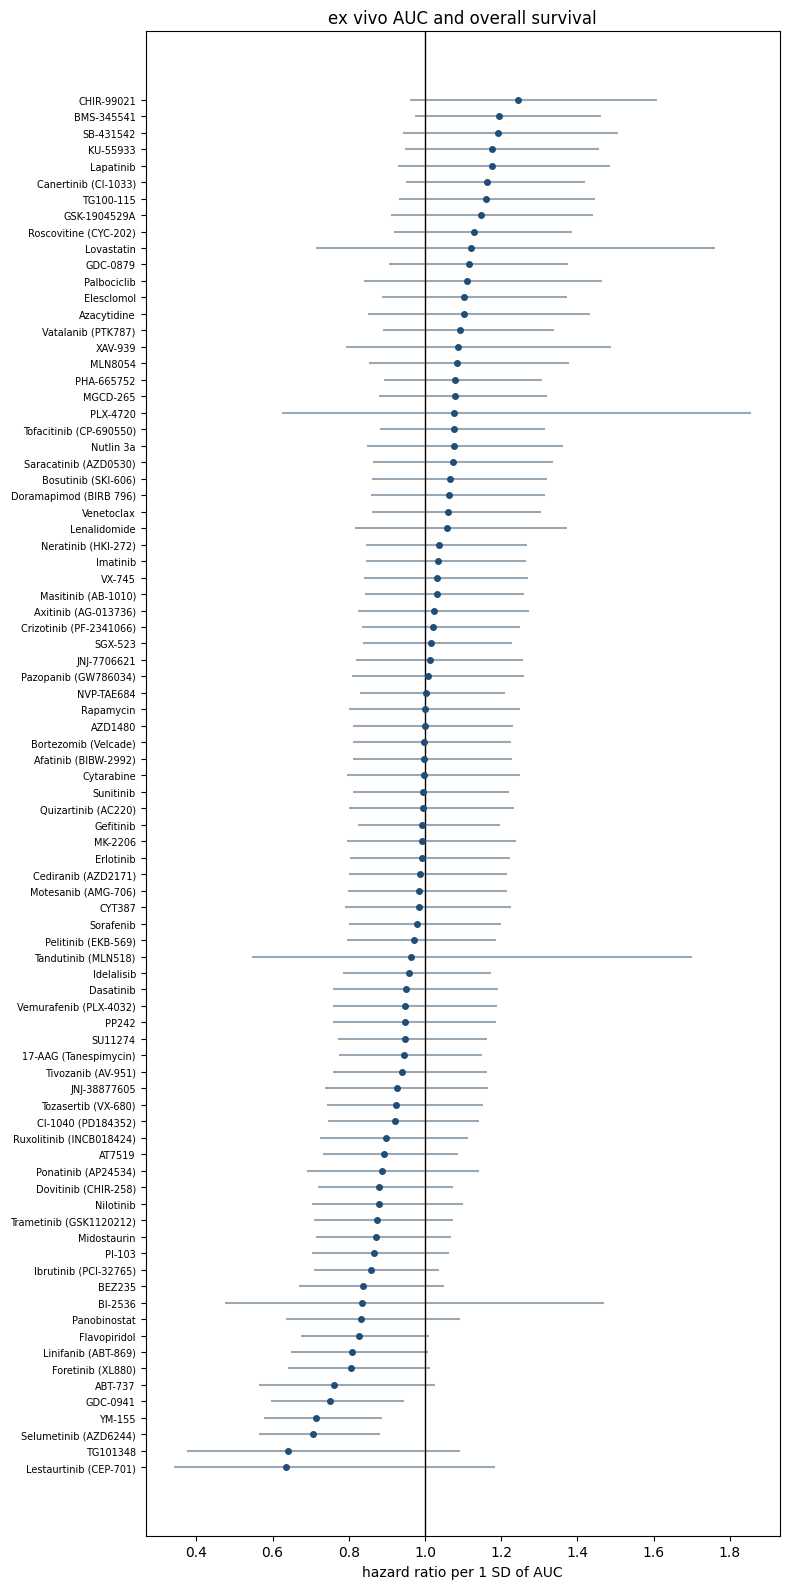

In [4]:
plot = out.sort_values('HR_per_SD')
fig, ax = plt.subplots(figsize=(8, 16))
y = range(len(plot))
ax.errorbar(plot.HR_per_SD, y,
            xerr=[plot.HR_per_SD - plot.lo, plot.hi - plot.HR_per_SD],
            fmt='o', color='#1f4e79', ecolor='#9aa8b5', markersize=4, capsize=0)
ax.axvline(1, color='black', lw=1)
ax.set_yticks(list(y))
ax.set_yticklabels(plot.drug, fontsize=7)
ax.set_xlabel('hazard ratio per 1 SD of AUC')
ax.set_title('ex vivo AUC and overall survival')
plt.tight_layout()
plt.show()

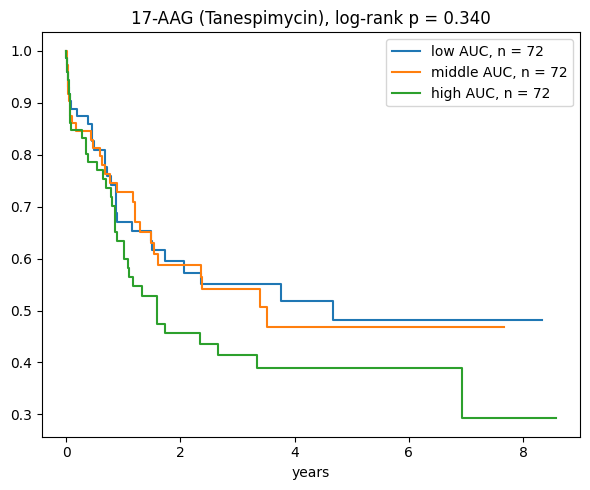

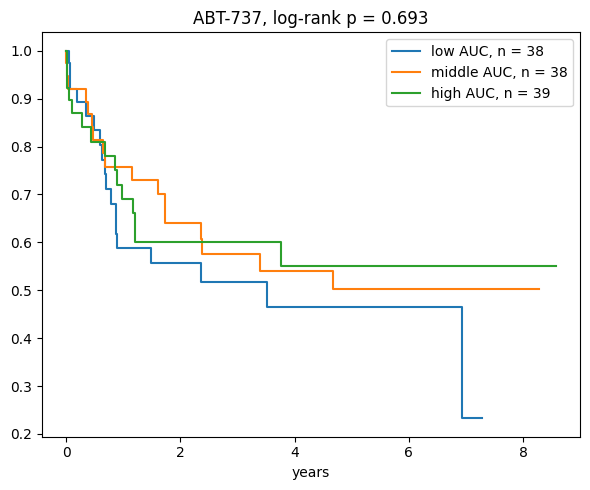

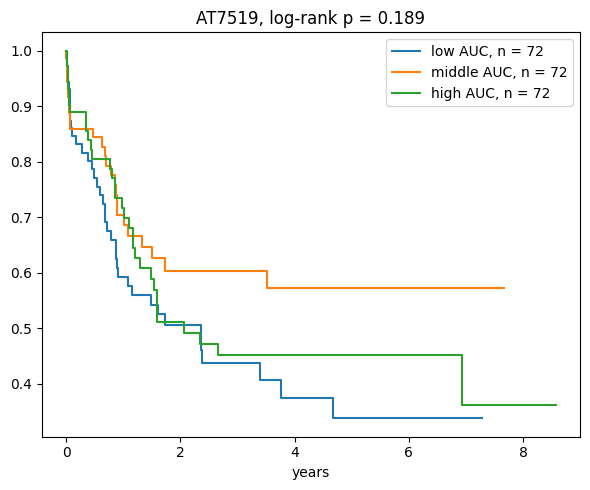

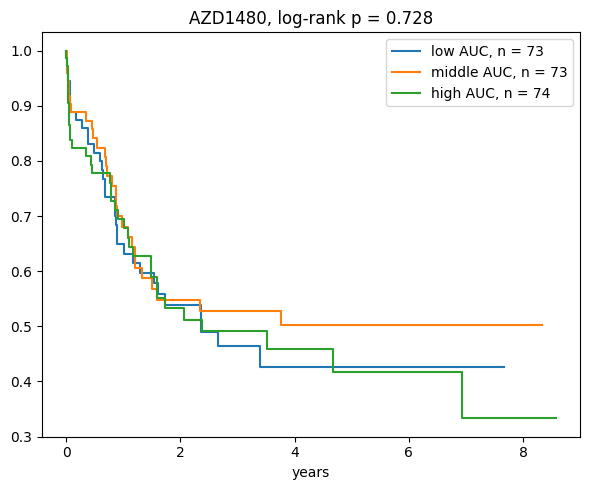

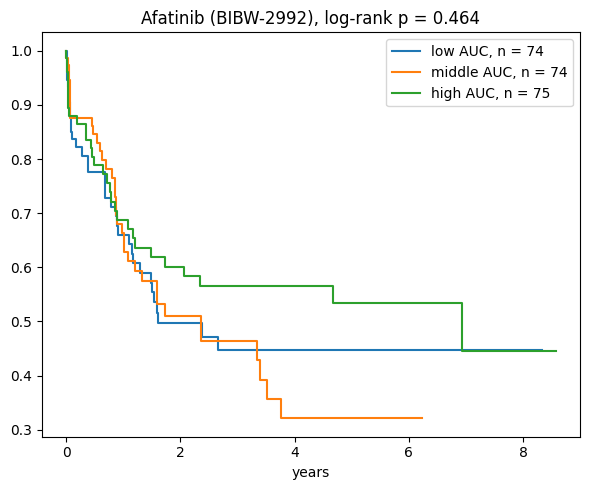

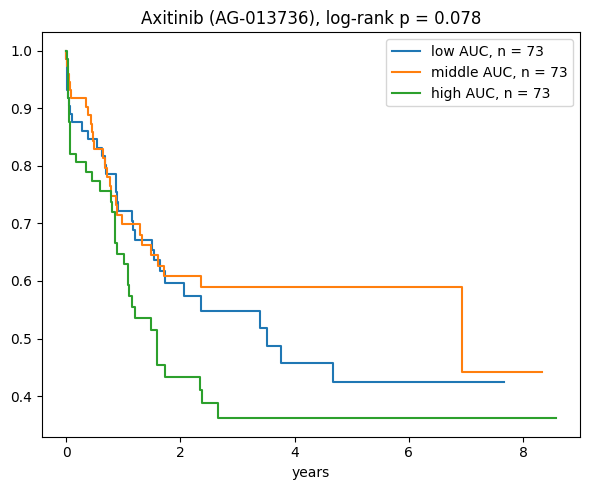

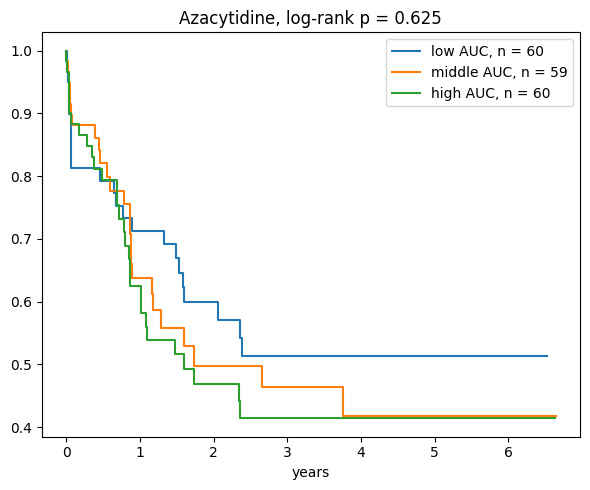

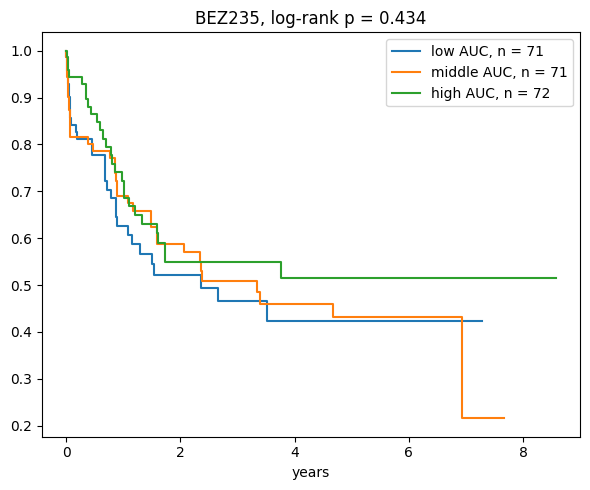

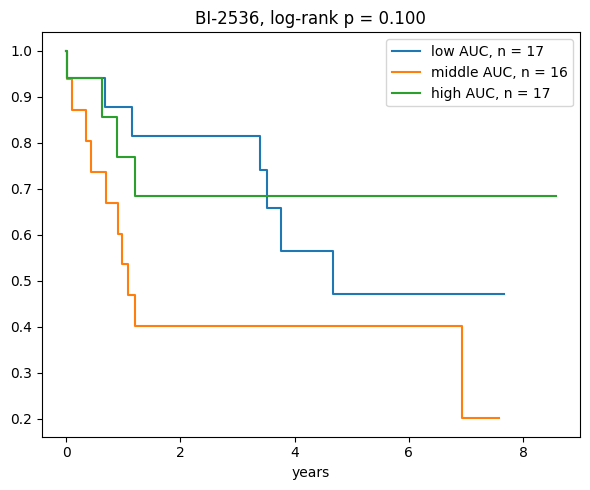

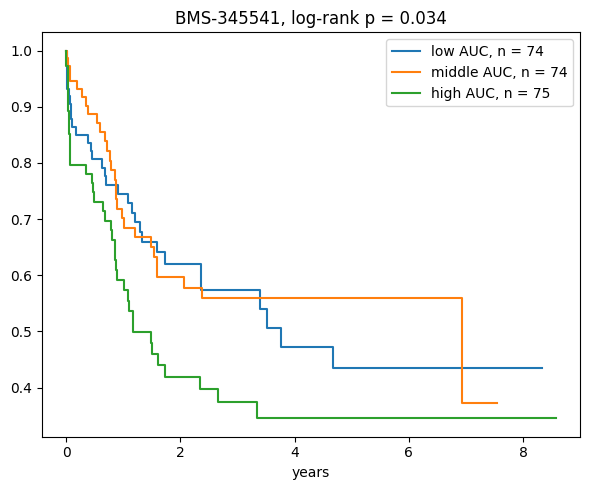

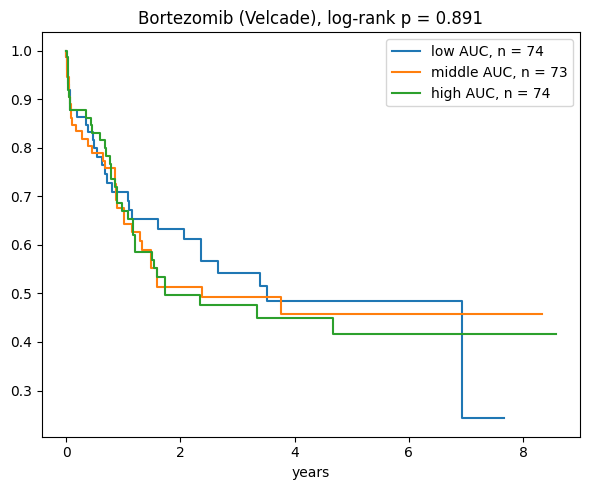

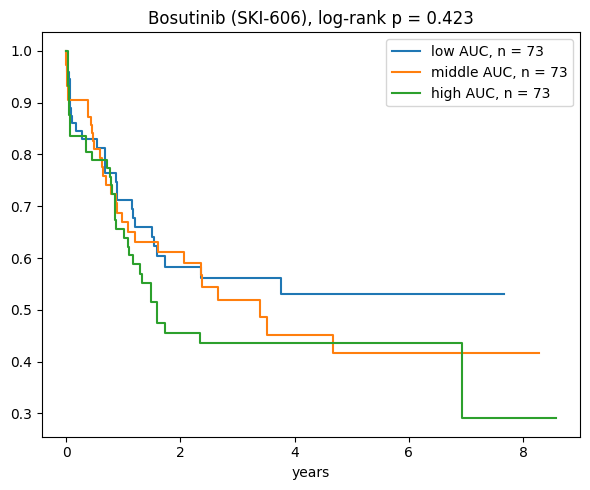

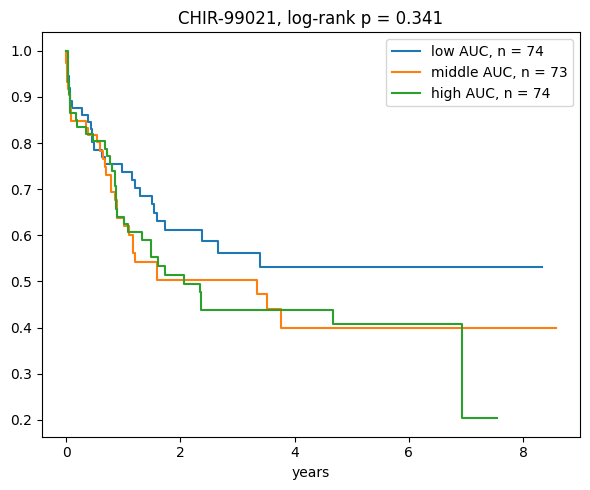

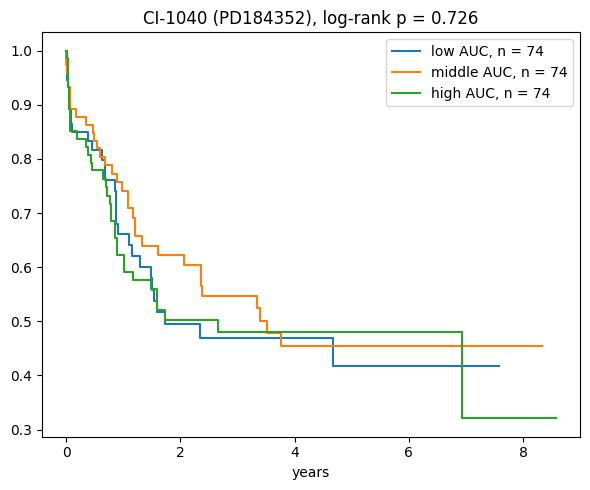

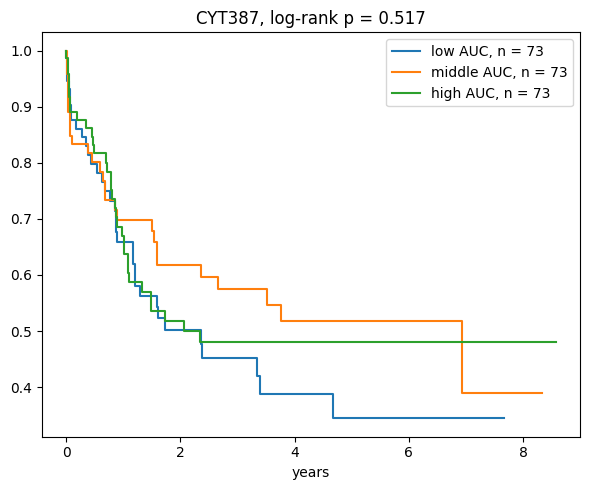

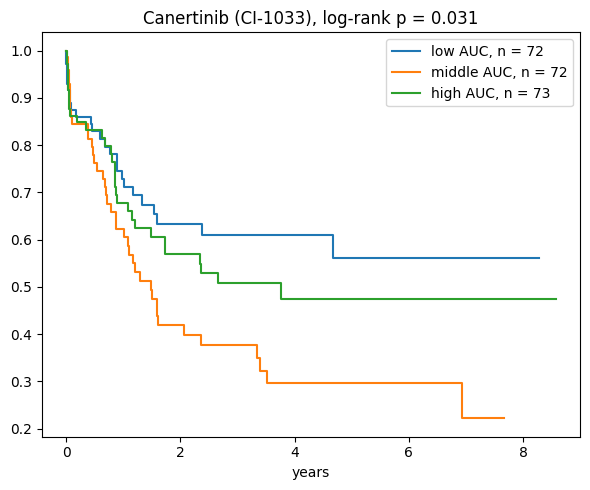

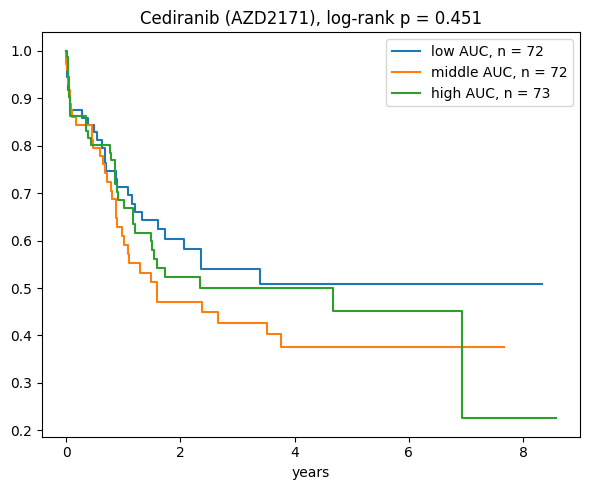

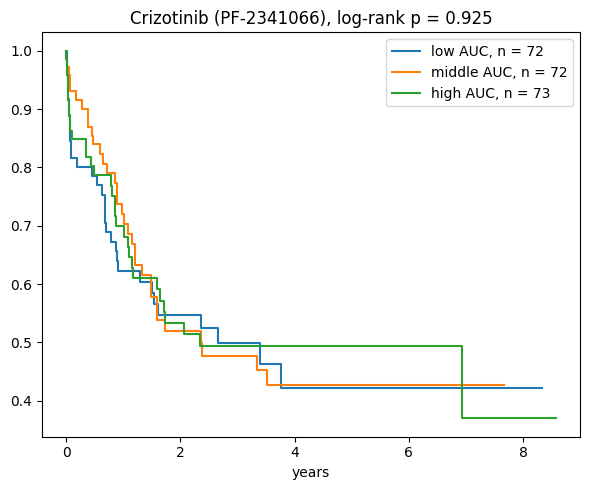

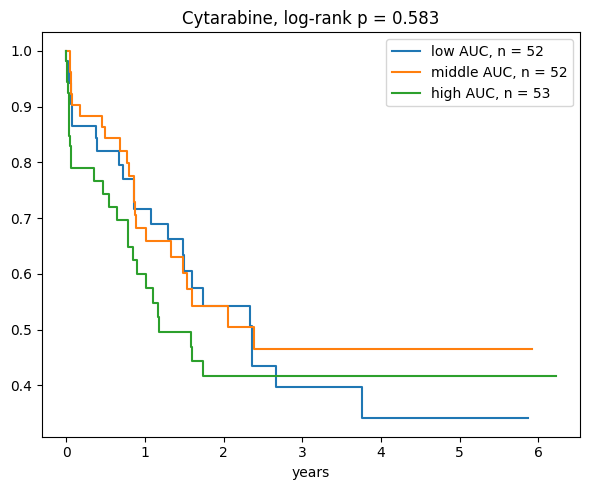

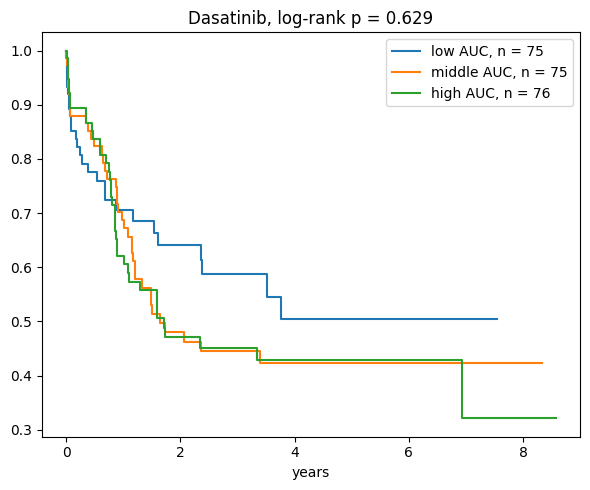

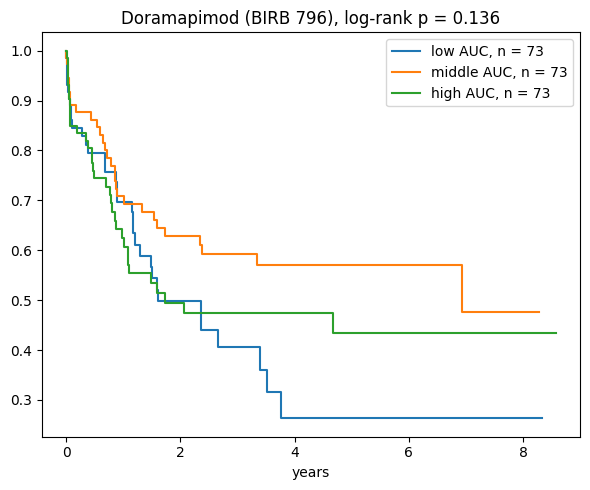

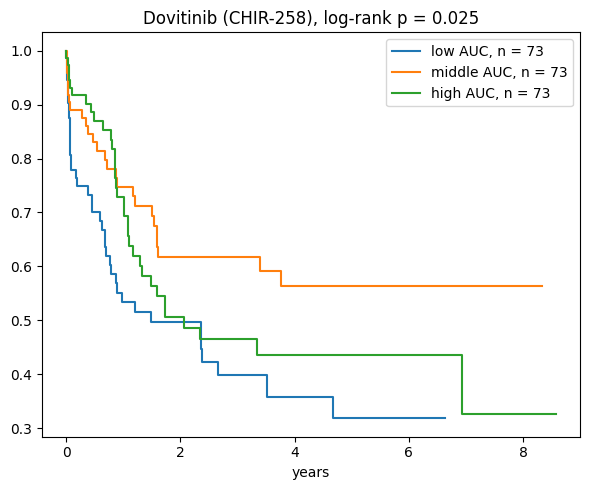

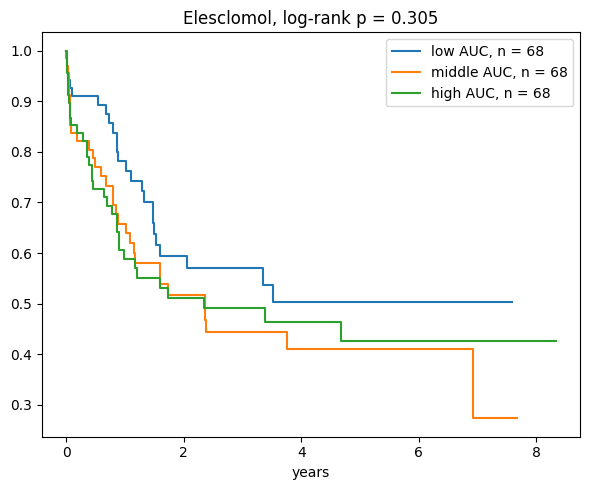

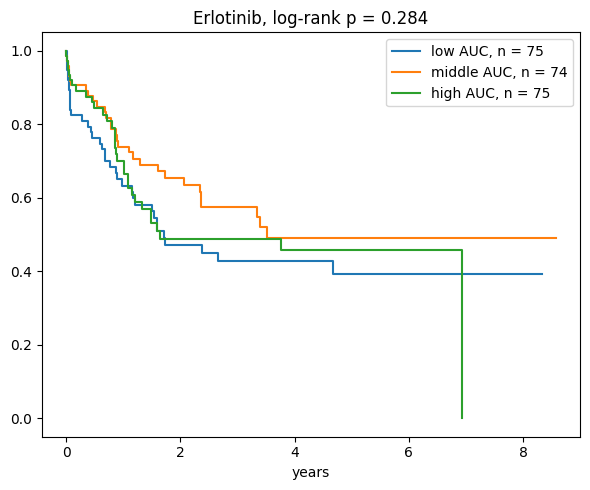

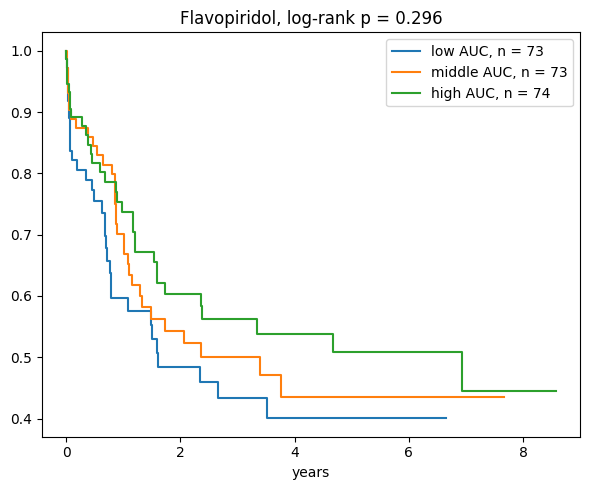

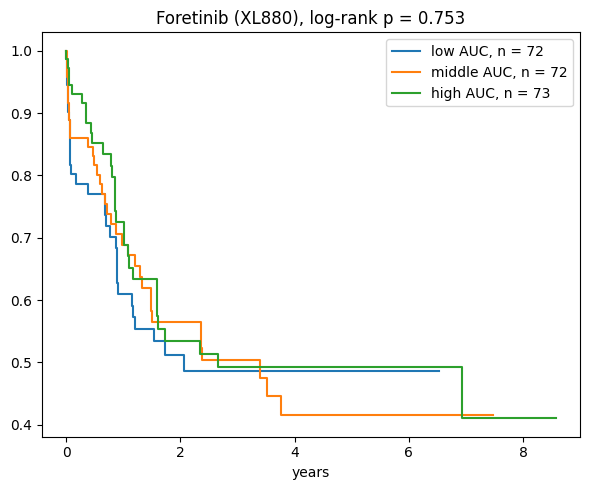

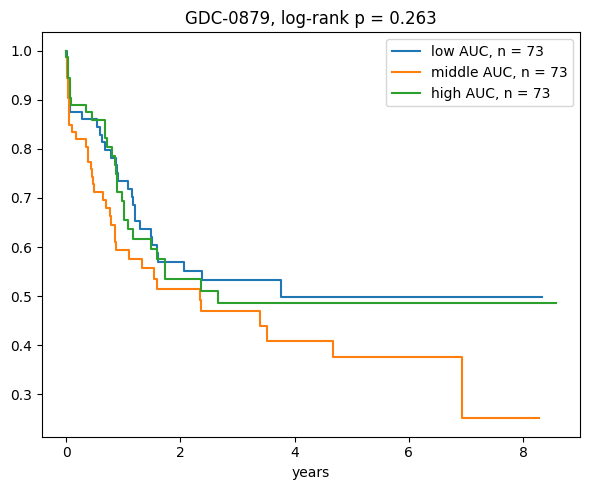

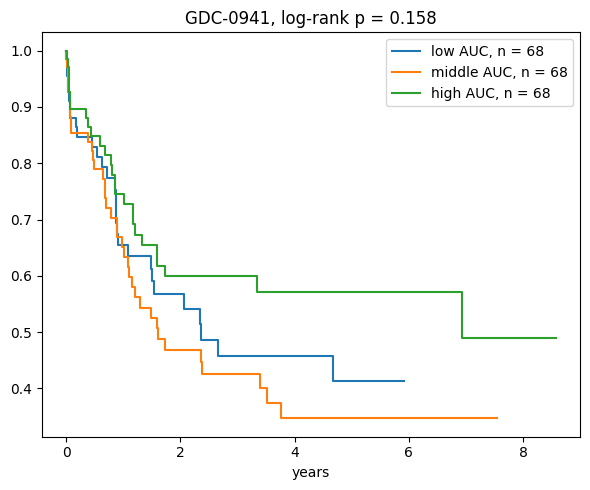

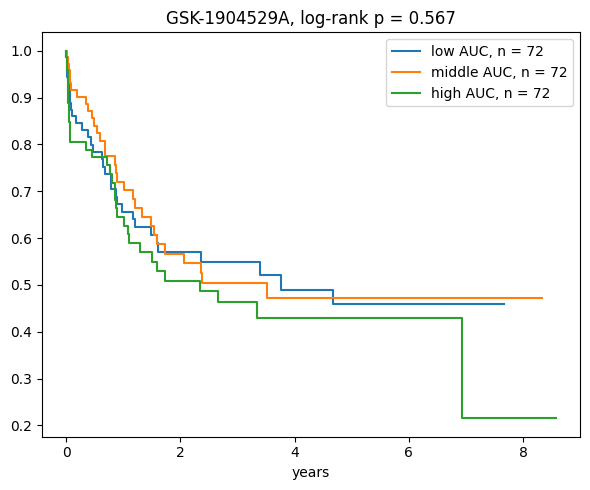

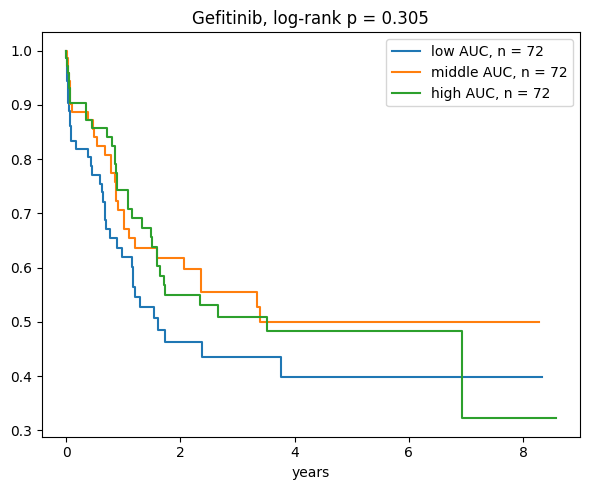

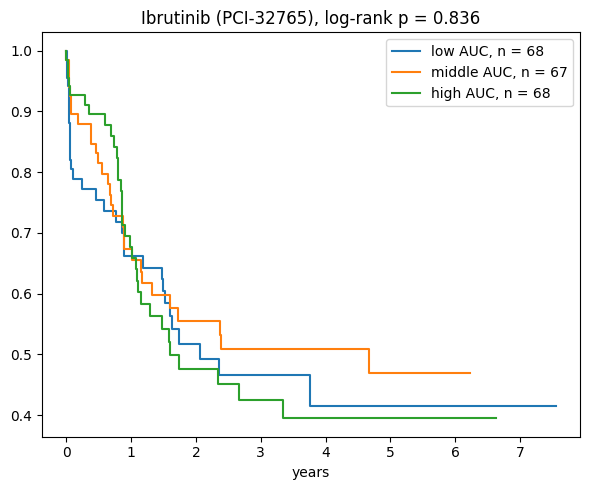

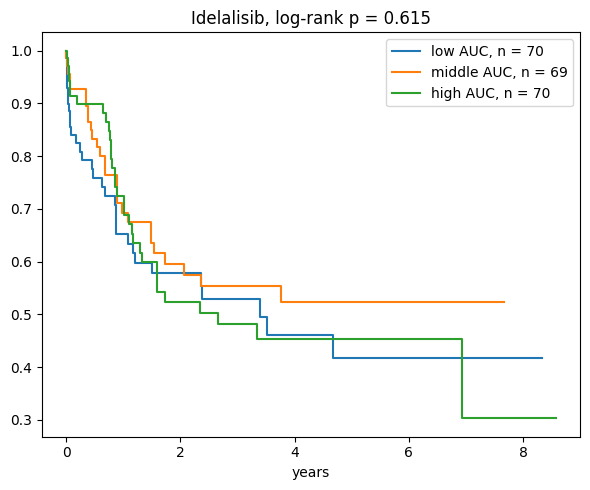

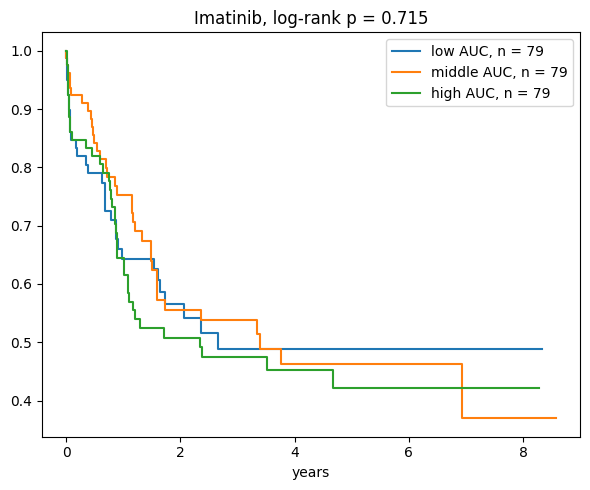

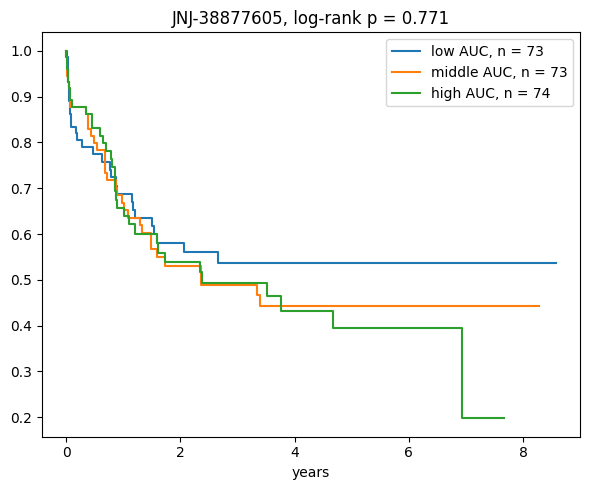

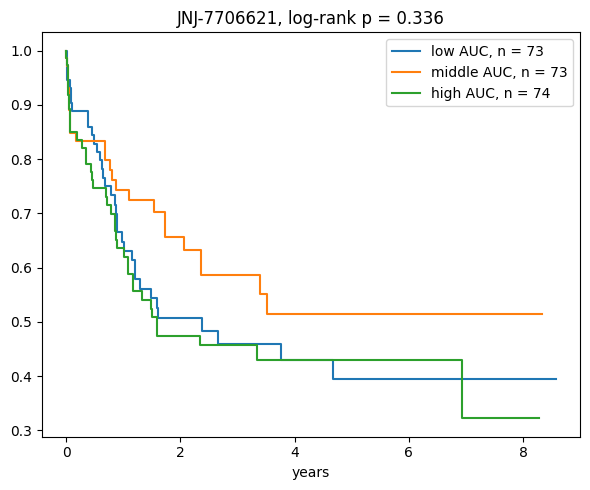

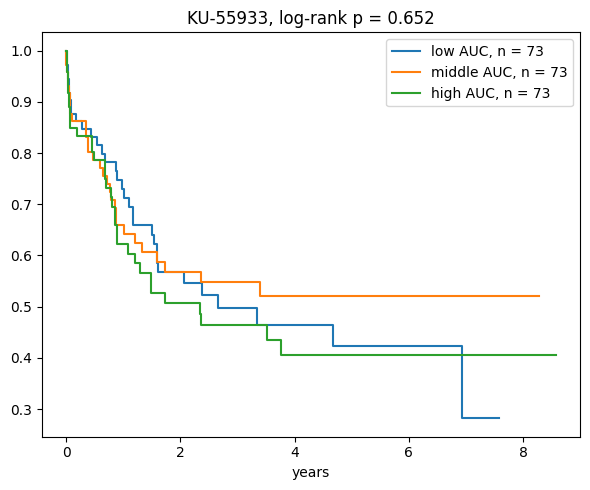

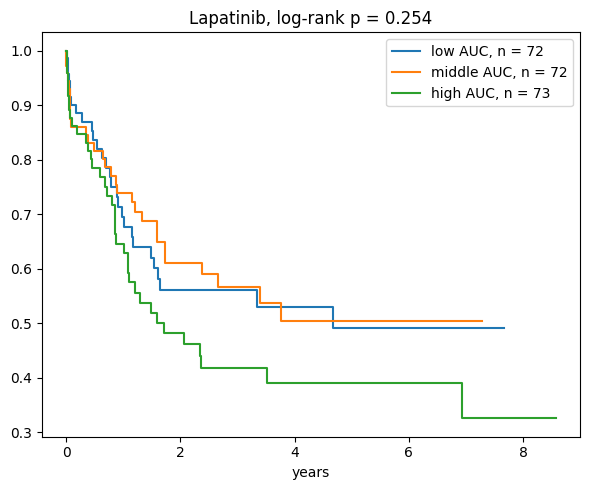

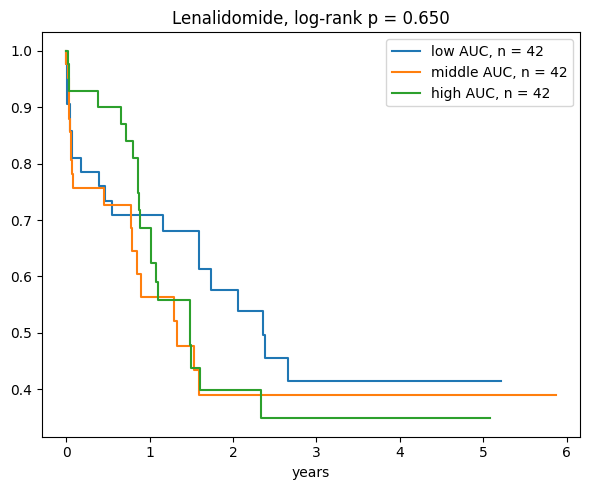

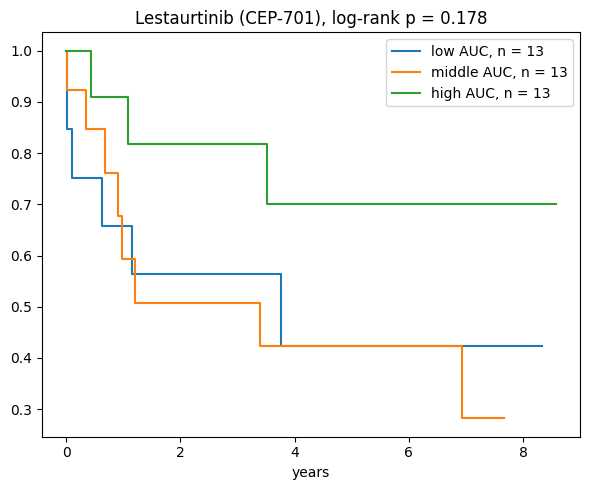

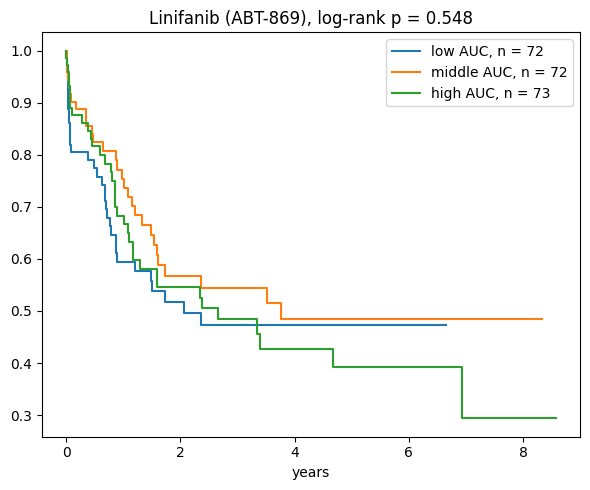

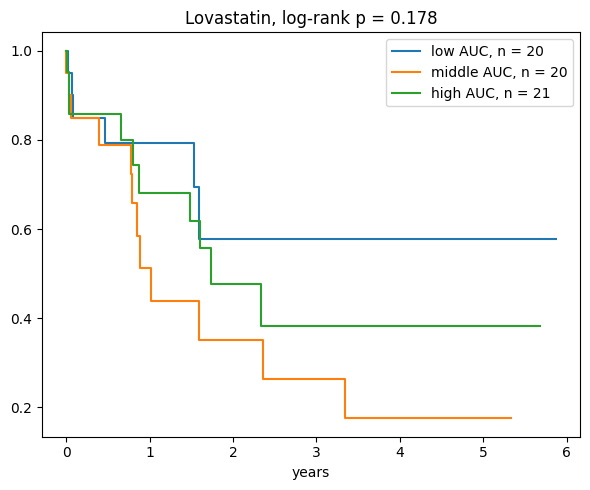

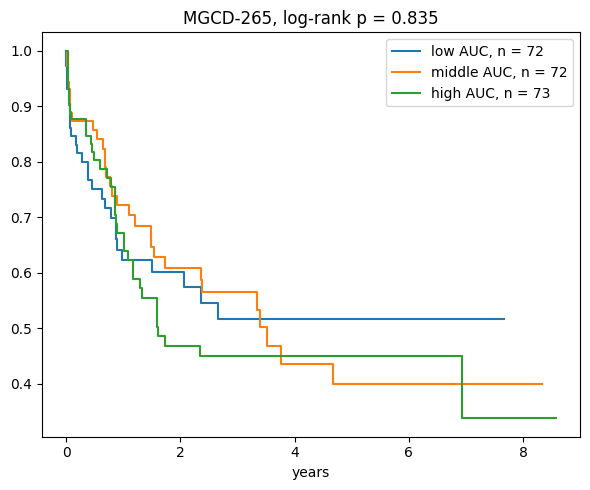

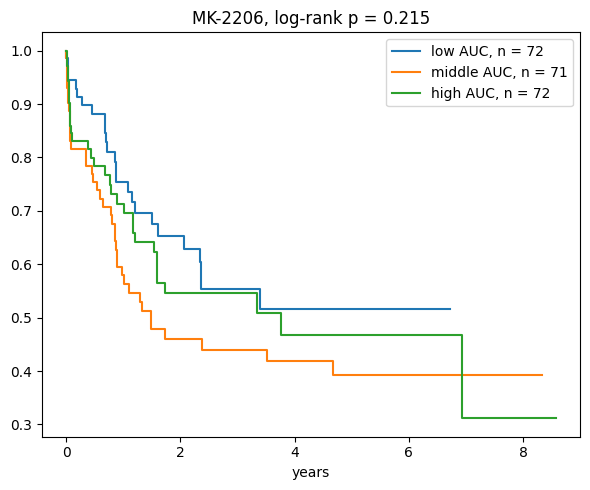

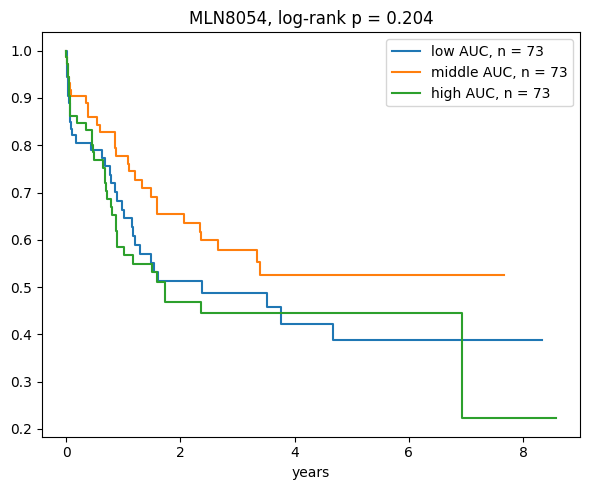

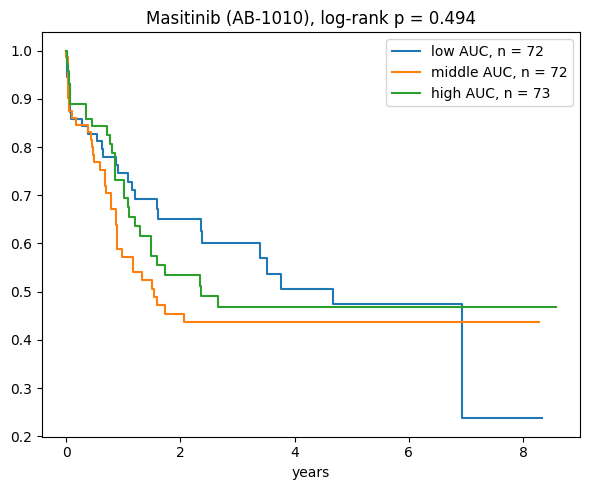

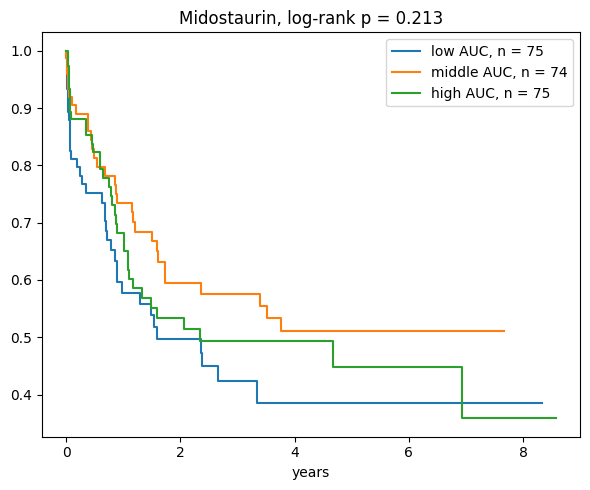

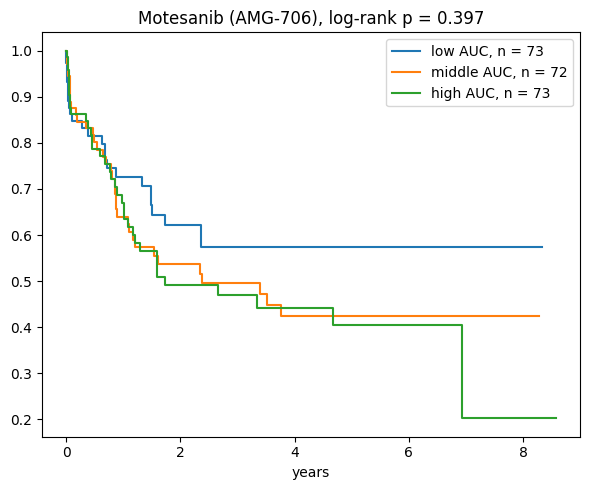

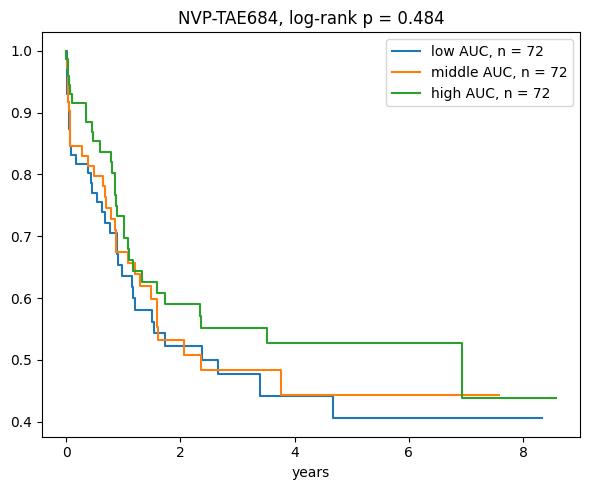

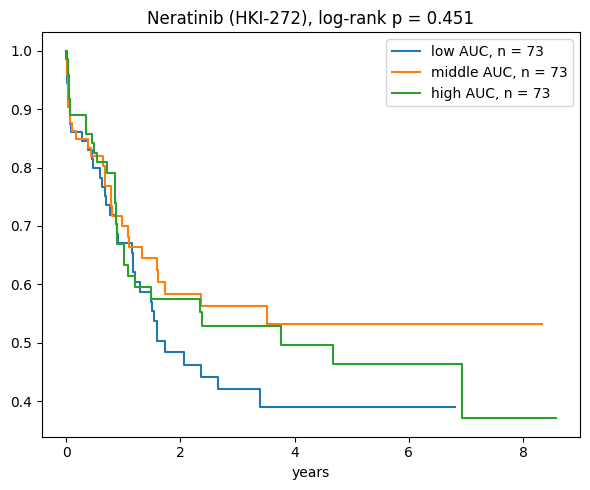

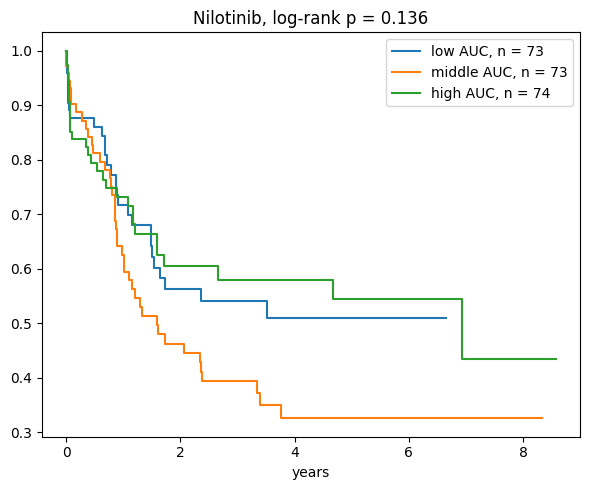

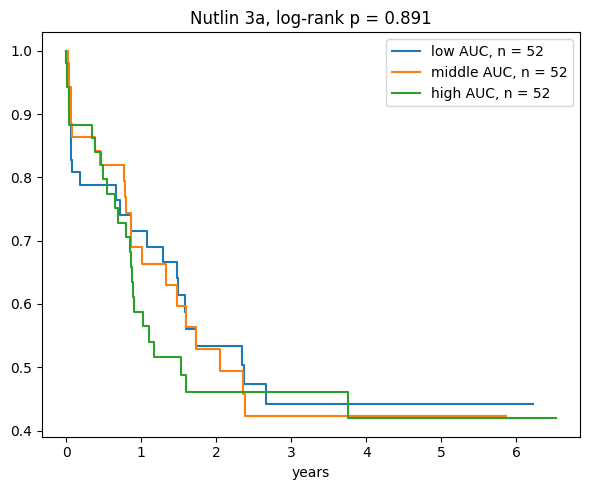

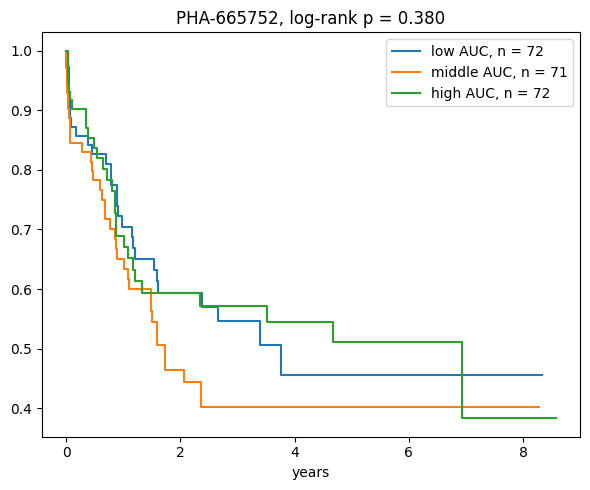

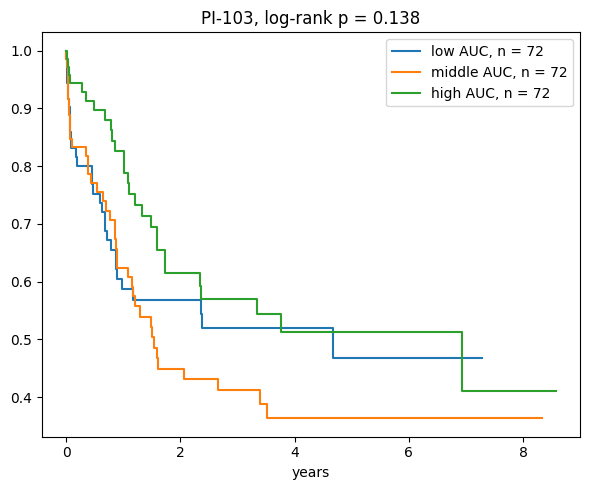

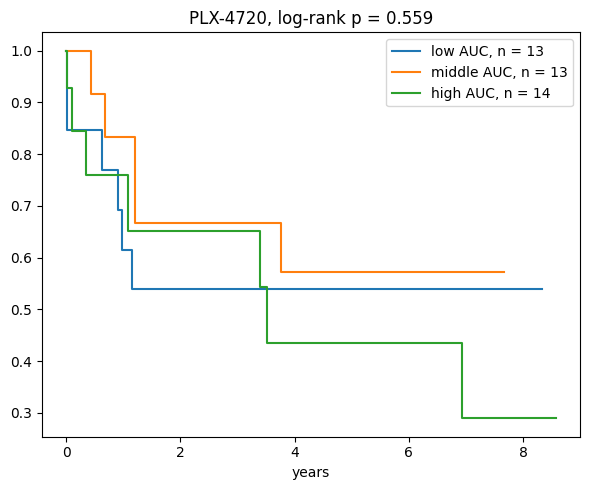

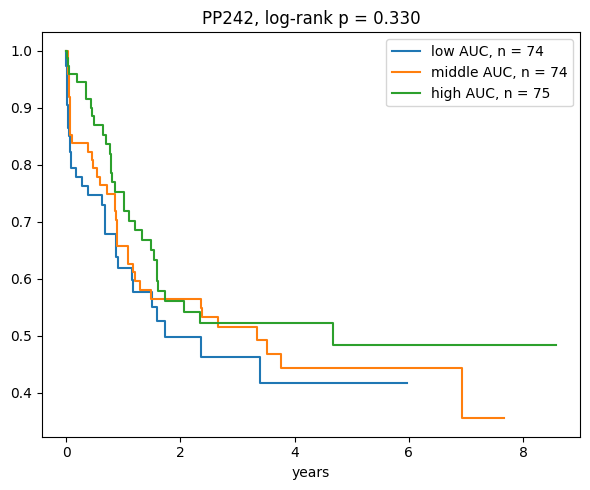

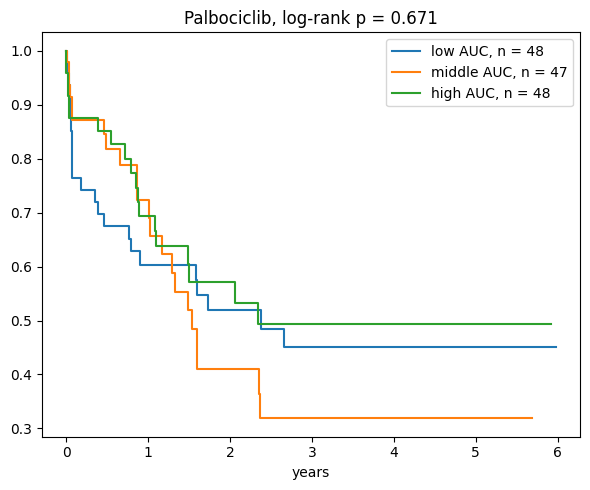

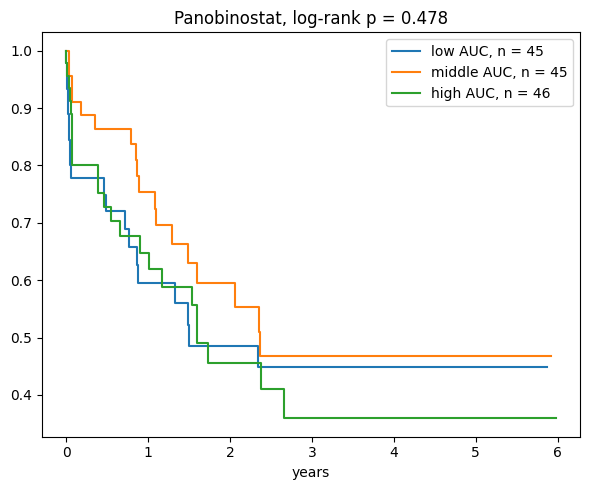

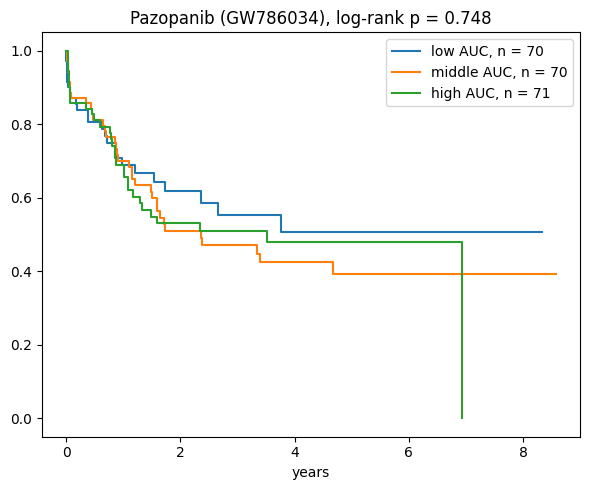

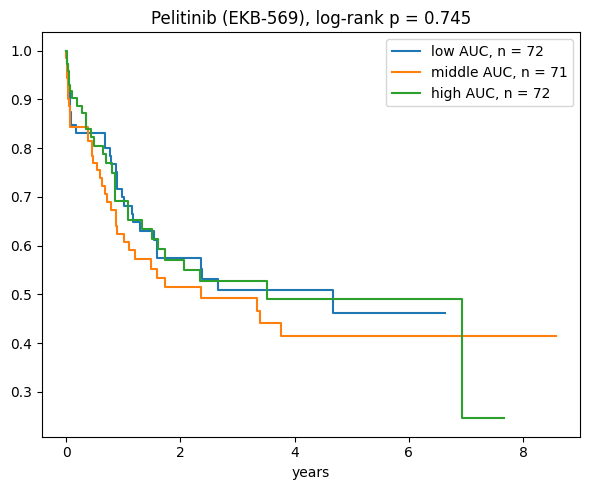

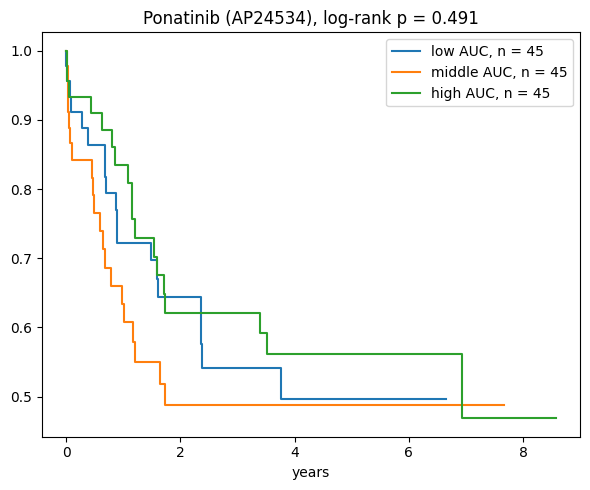

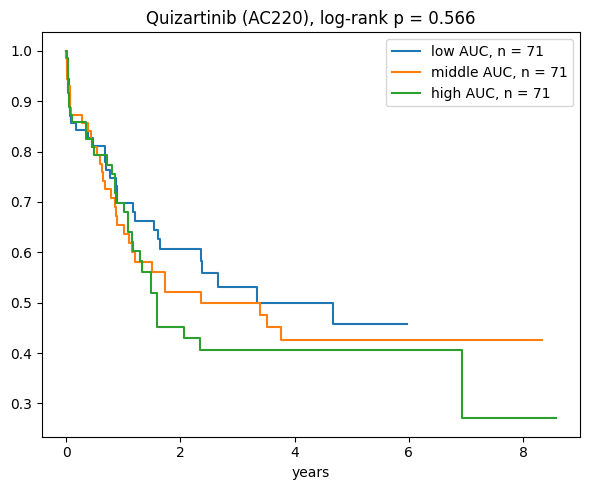

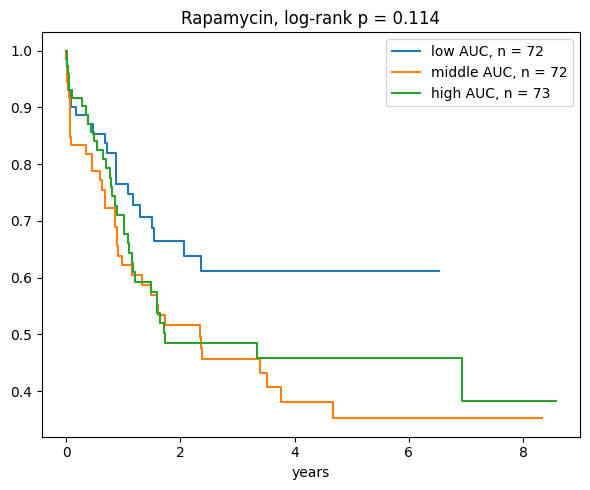

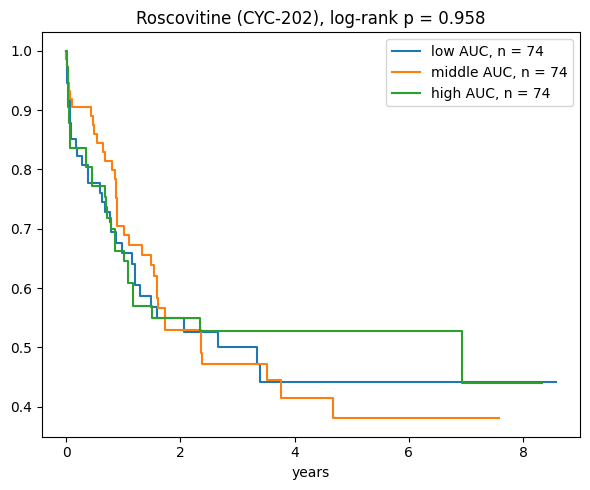

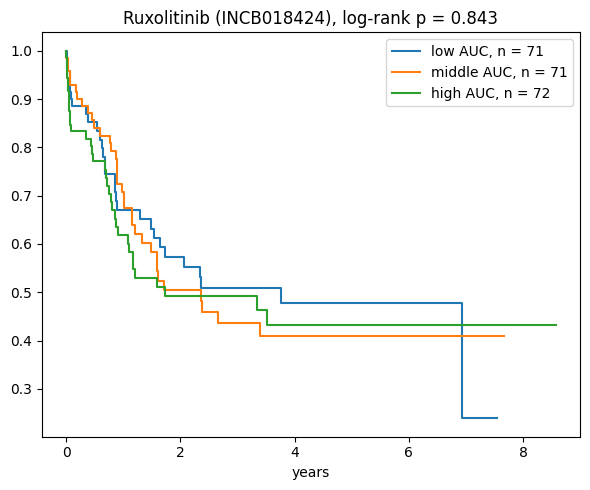

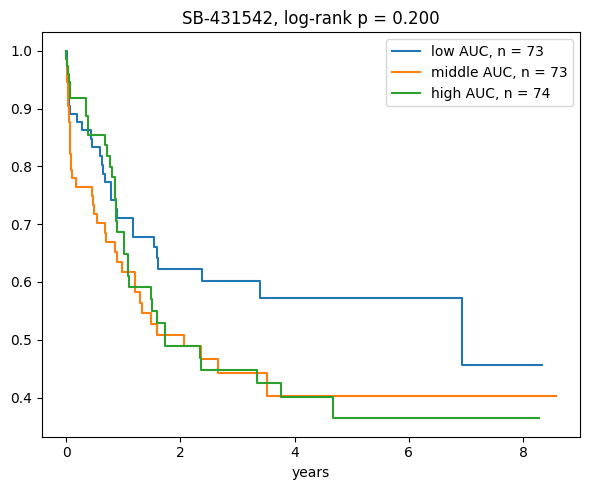

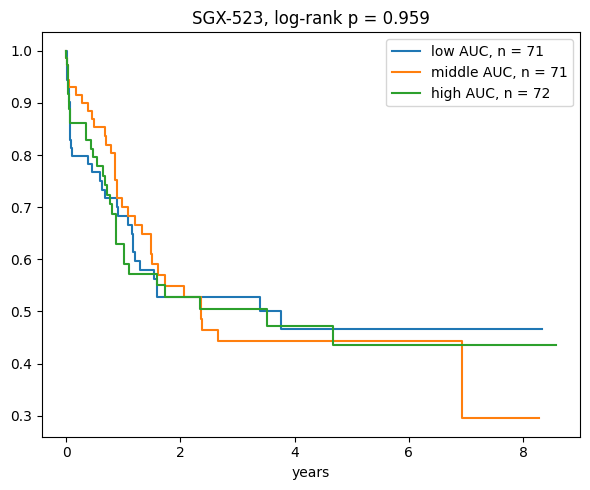

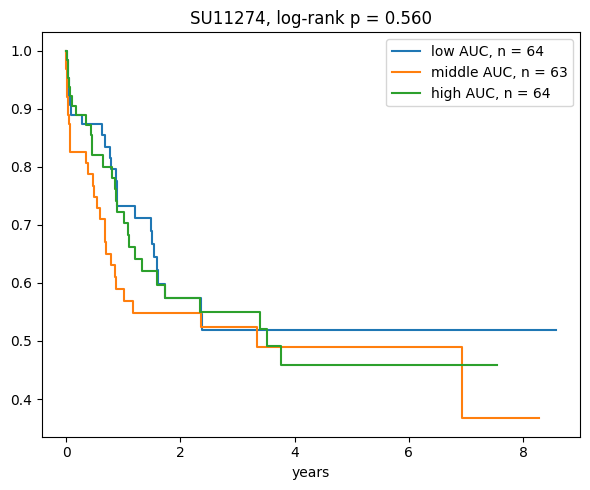

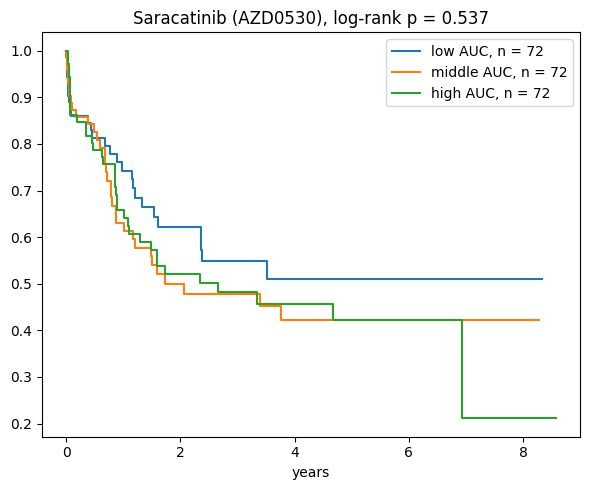

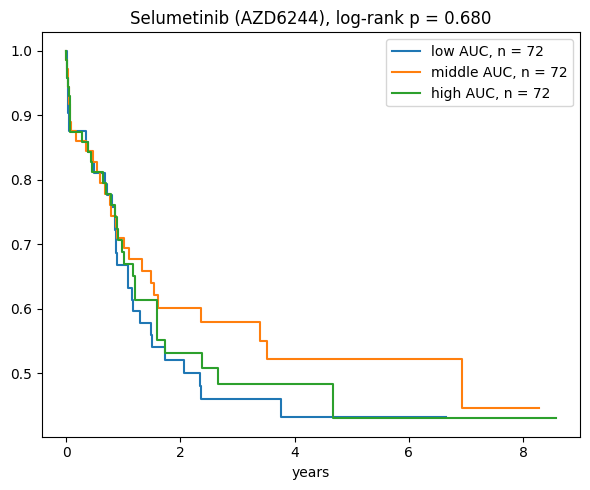

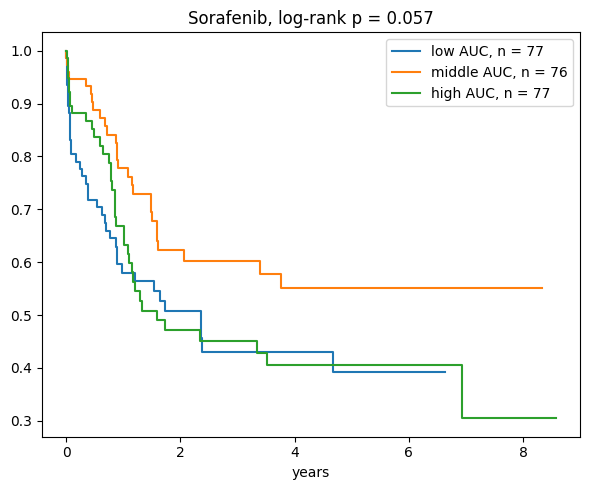

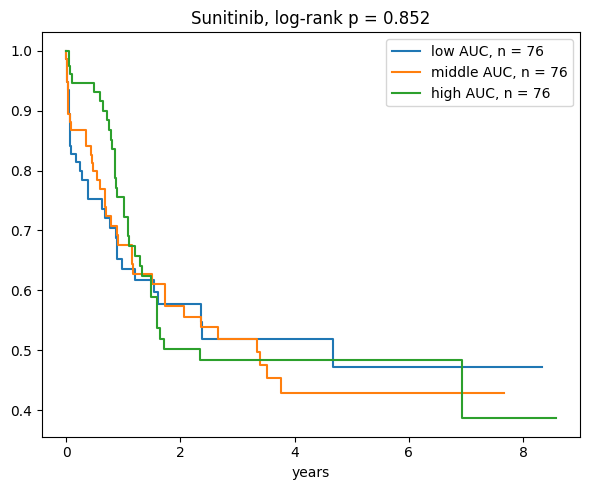

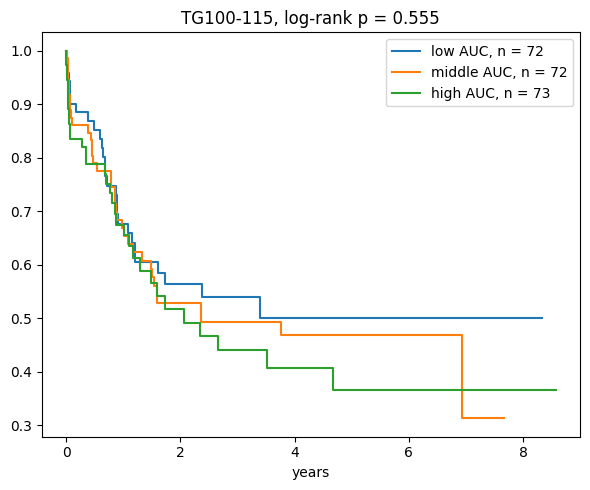

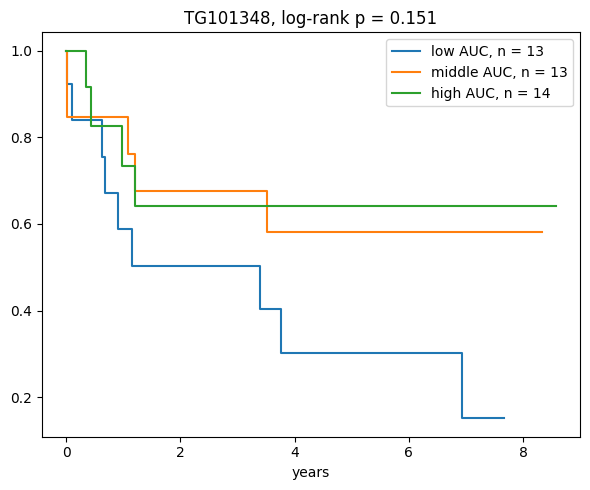

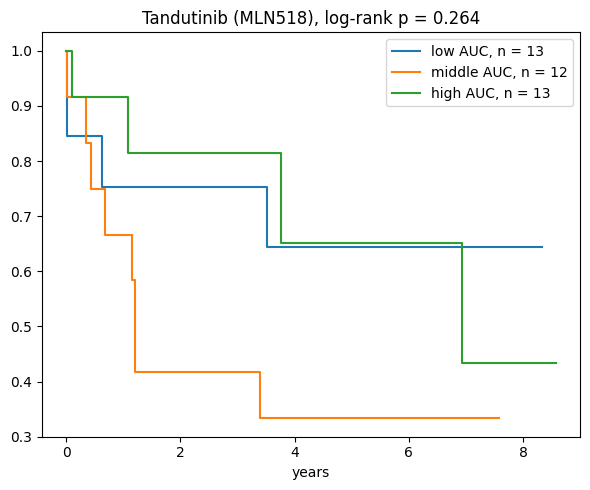

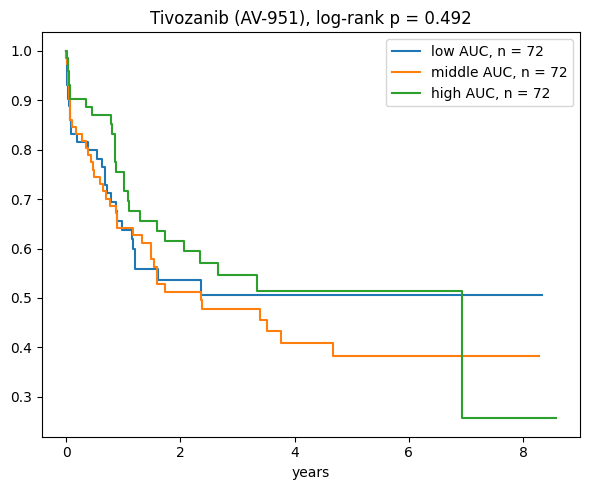

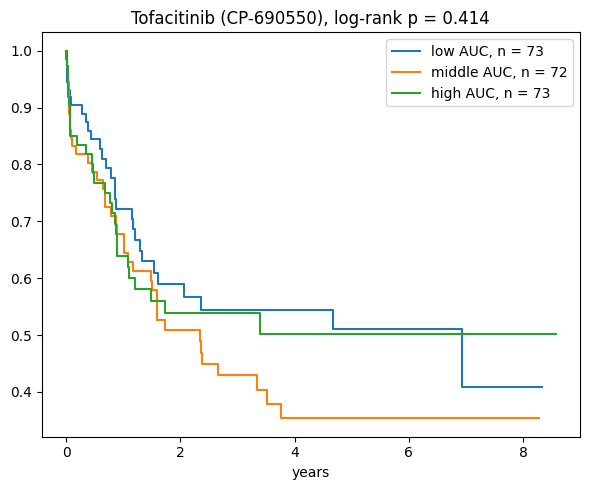

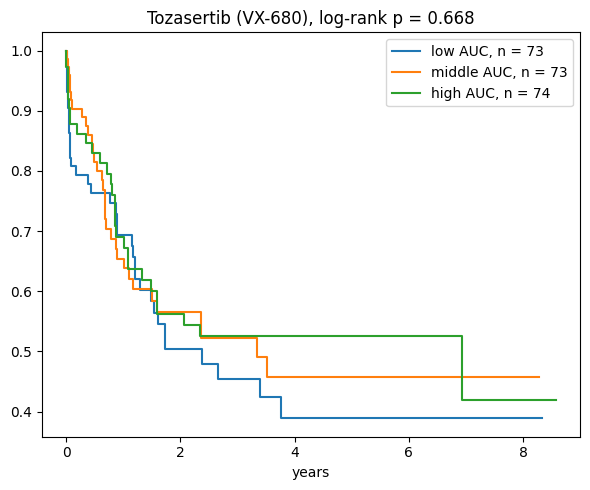

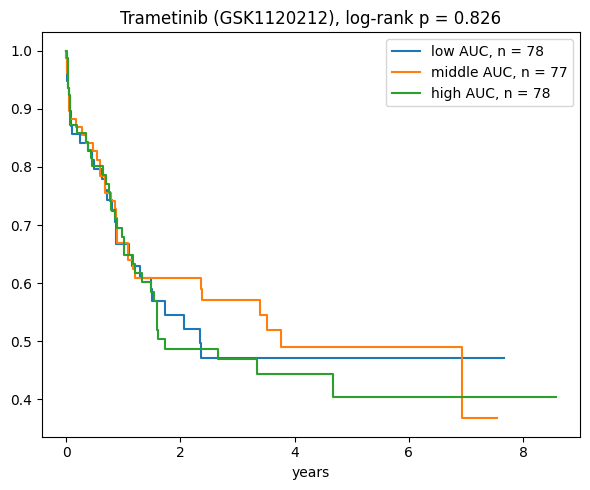

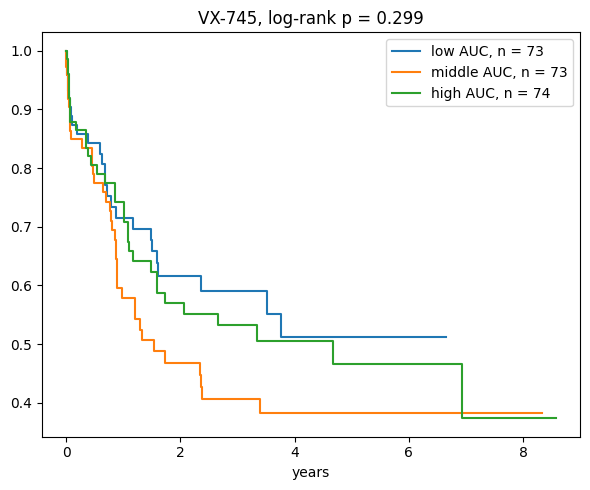

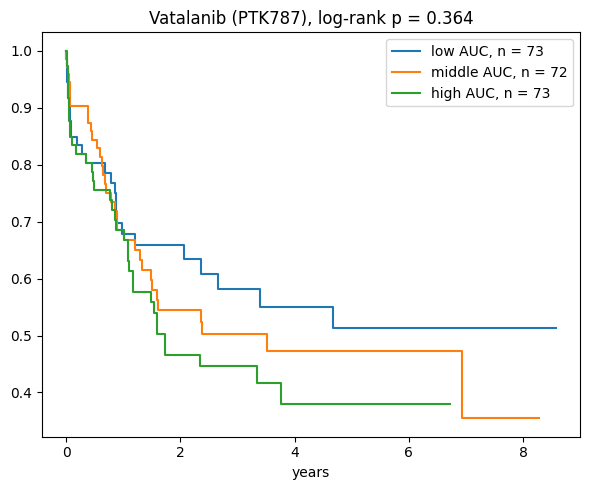

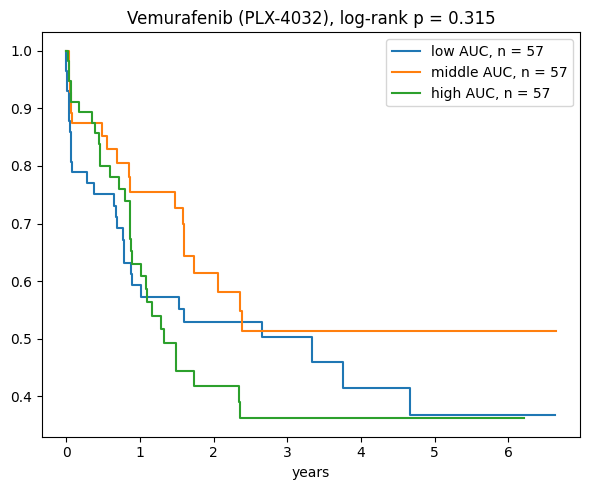

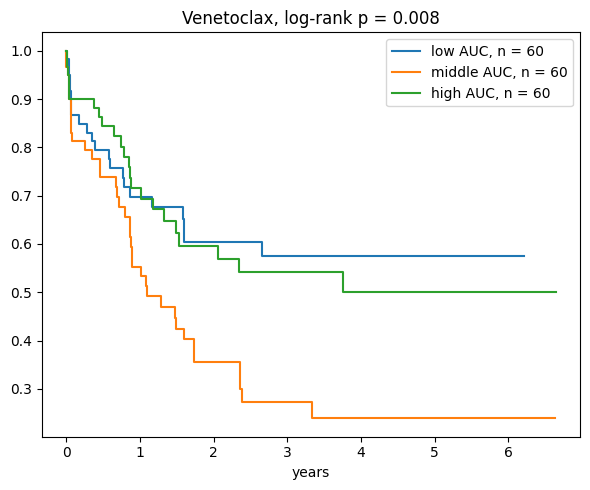

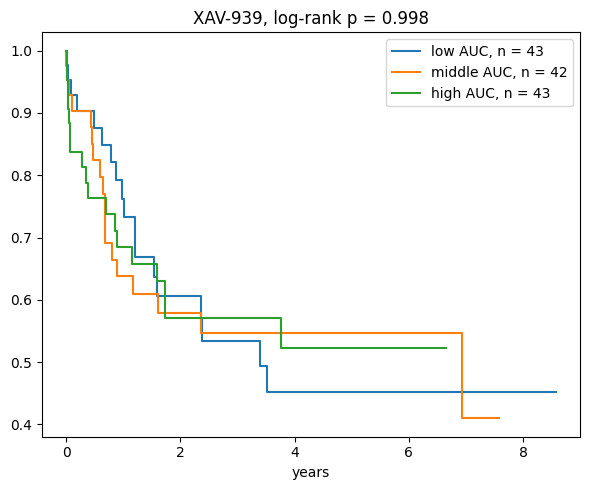

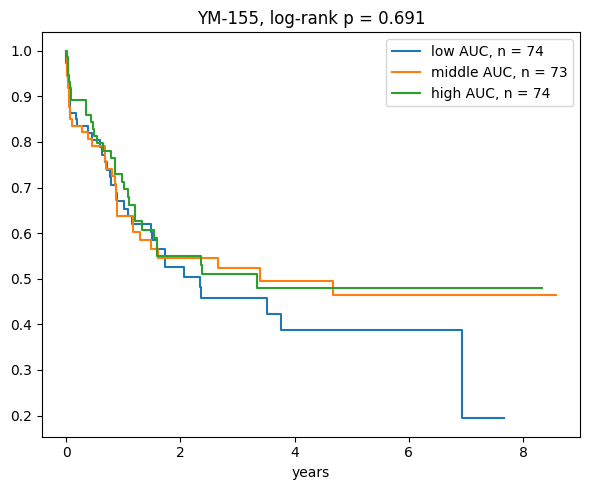

In [5]:
# Kaplan-Meier. Within each drug, patients are split into equal thirds by AUC.
for name, one in drugs.groupby('inhibitor'):
    auc = one.groupby('dbgap_subject_id')['auc'].mean()
    d = cohort.join(auc.rename('auc')).dropna(subset=['auc']).copy()
    d['band'] = pd.qcut(d.auc.rank(method='first'), 3, labels=['low AUC', 'middle AUC', 'high AUC'])
    fig, ax = plt.subplots(figsize=(6, 5))
    kmf = KaplanMeierFitter()
    for band in ['low AUC', 'middle AUC', 'high AUC']:
        sub = d[d.band == band]
        kmf.fit(sub.overallSurvival / 365.25, sub.E, label=f'{band}, n = {len(sub)}').plot_survival_function(ax=ax, ci_show=False)
    lr = multivariate_logrank_test(d.overallSurvival, d.band, d.E)
    ax.set_title(f'{name}, log-rank p = {lr.p_value:.3f}')
    ax.set_xlabel('years')
    plt.tight_layout()
    plt.show()

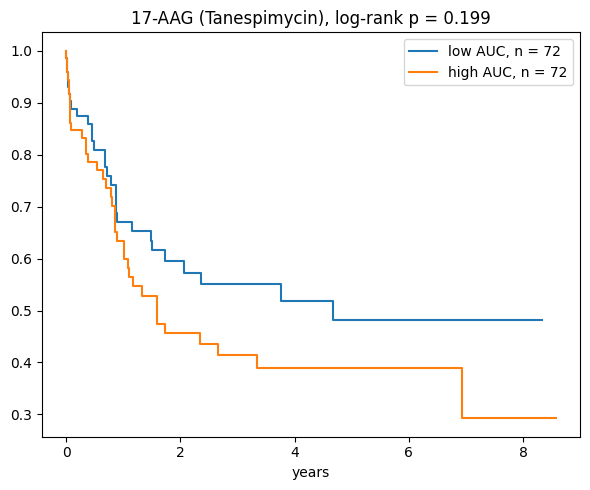

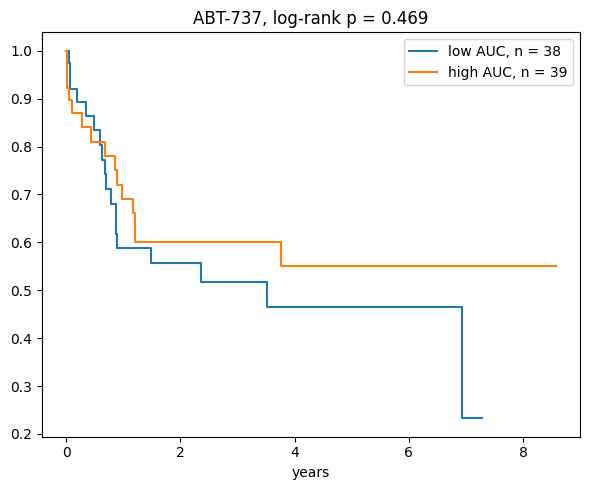

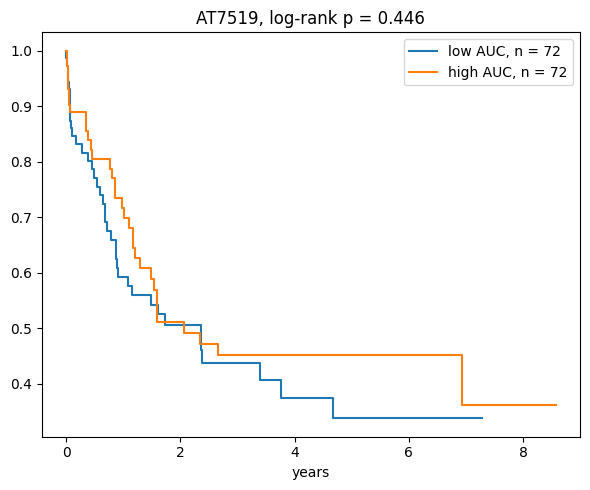

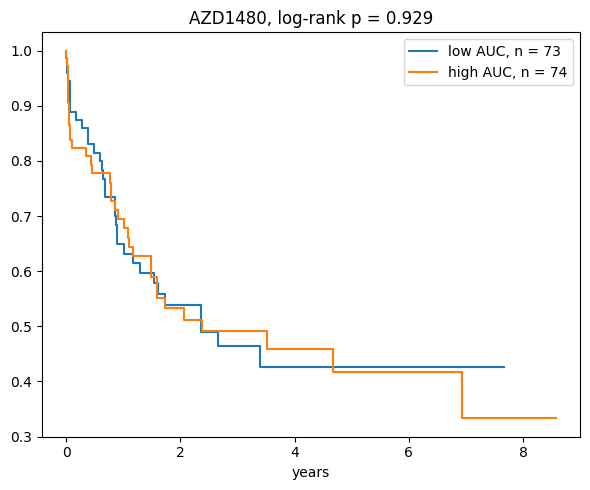

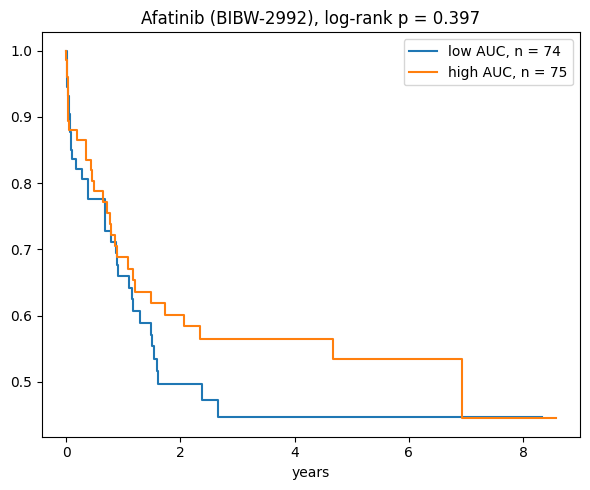

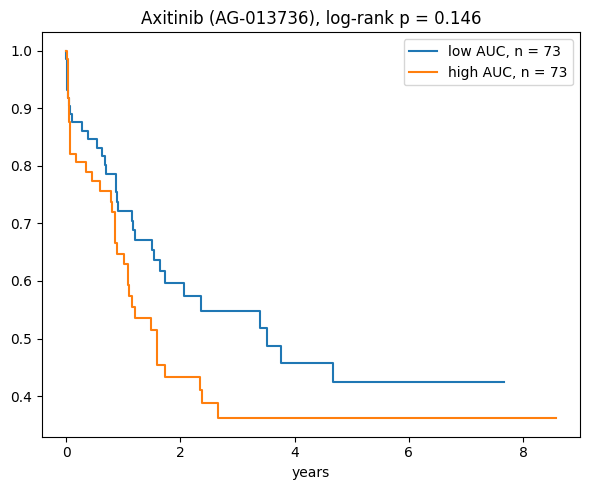

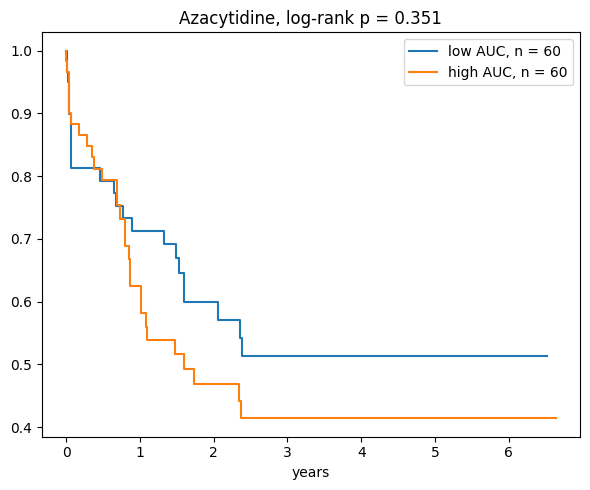

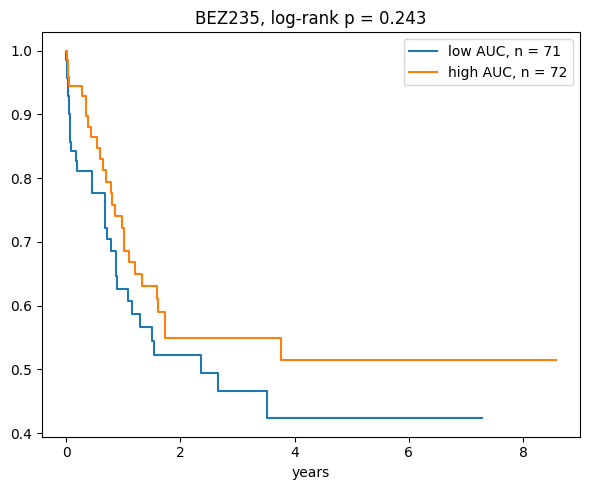

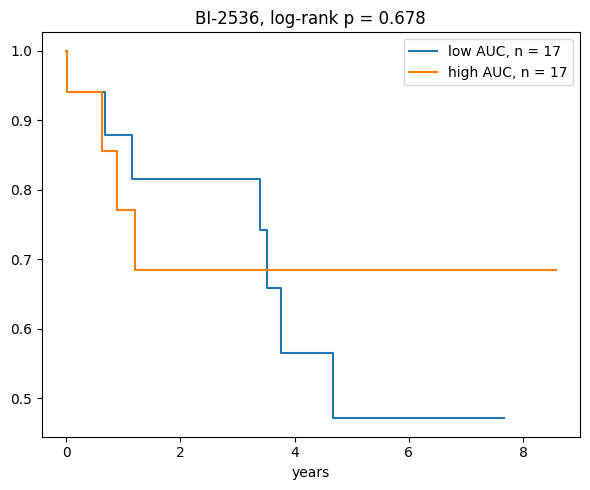

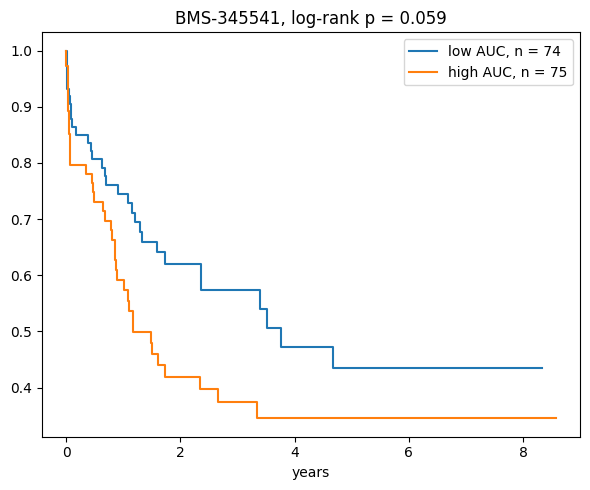

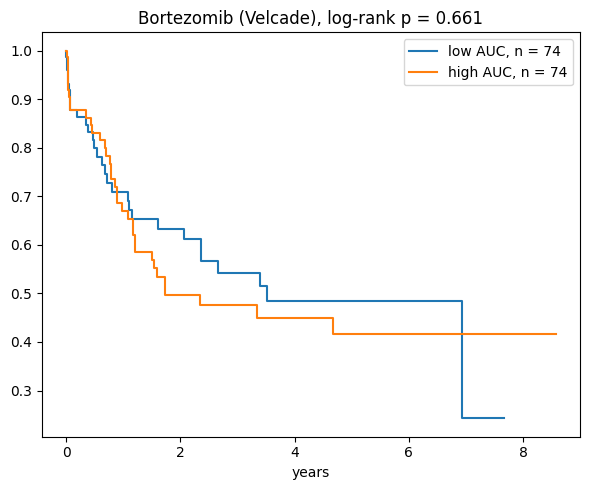

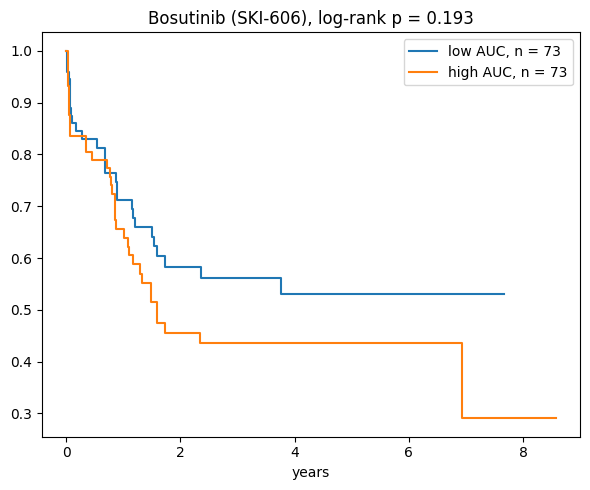

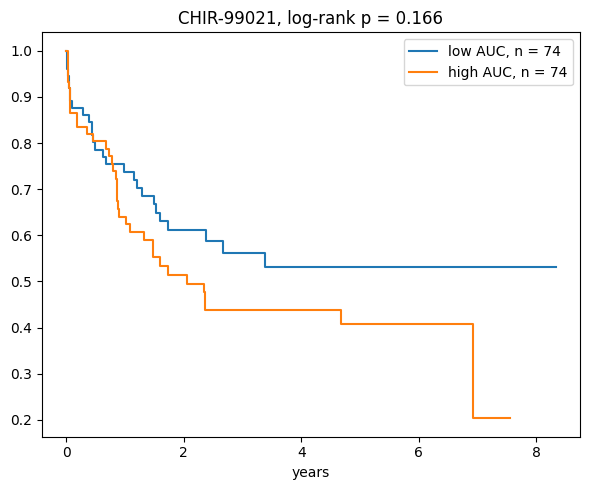

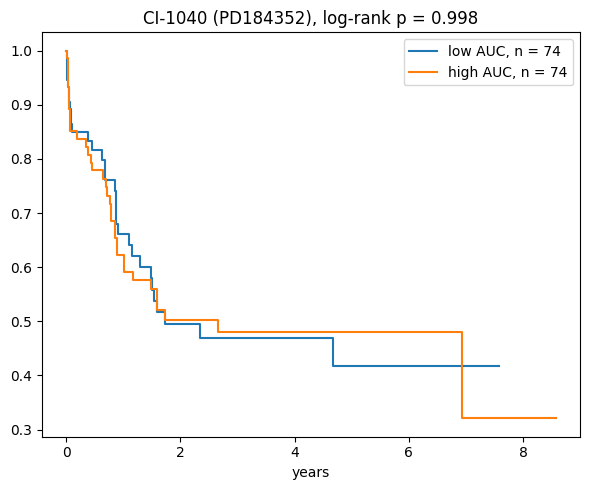

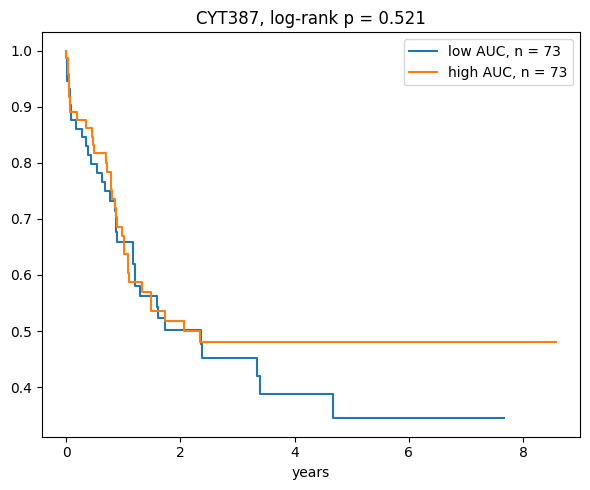

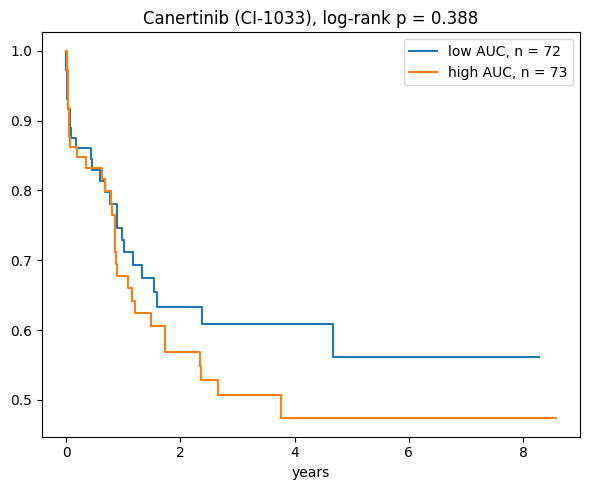

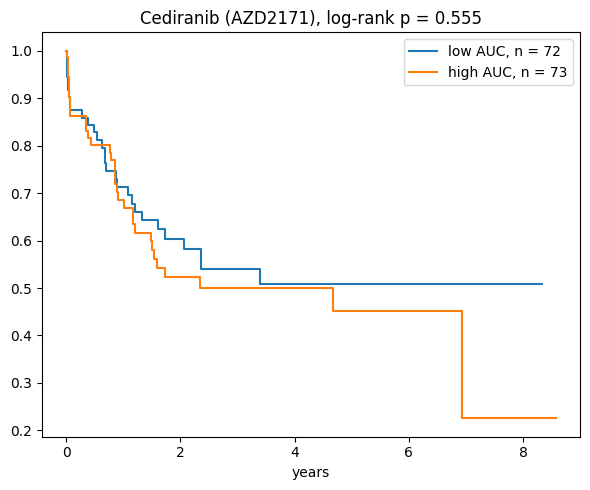

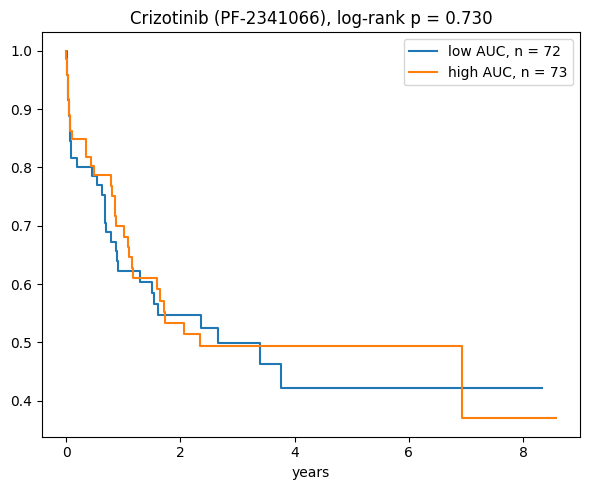

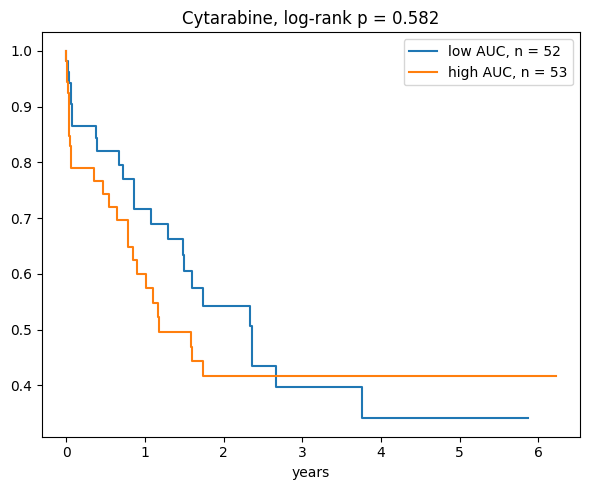

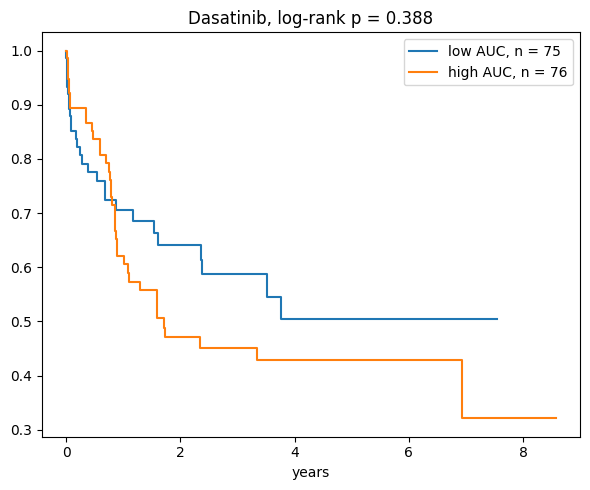

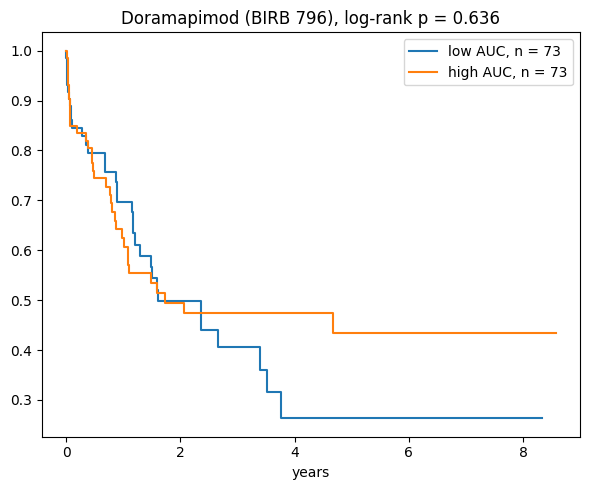

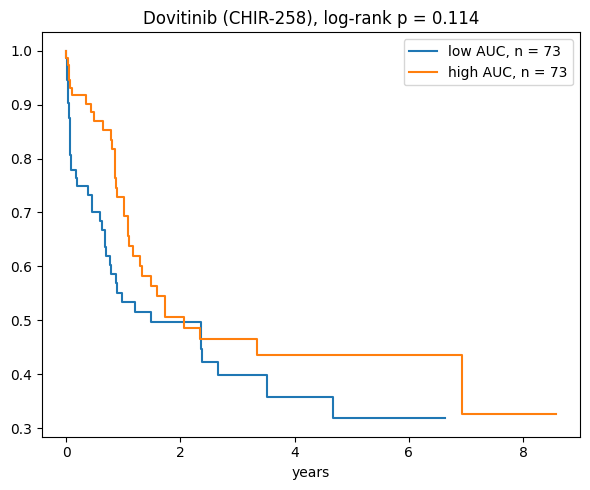

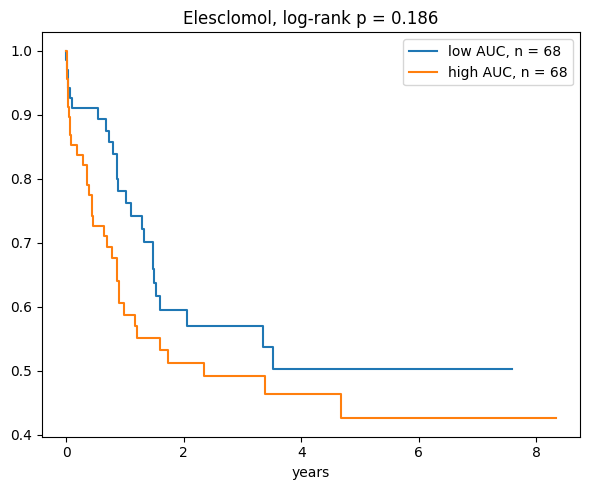

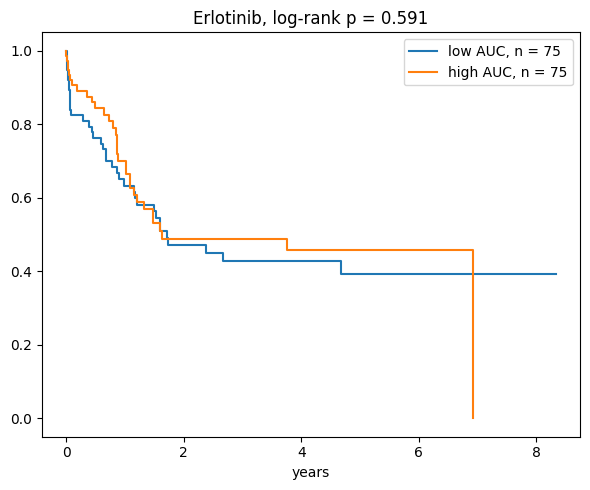

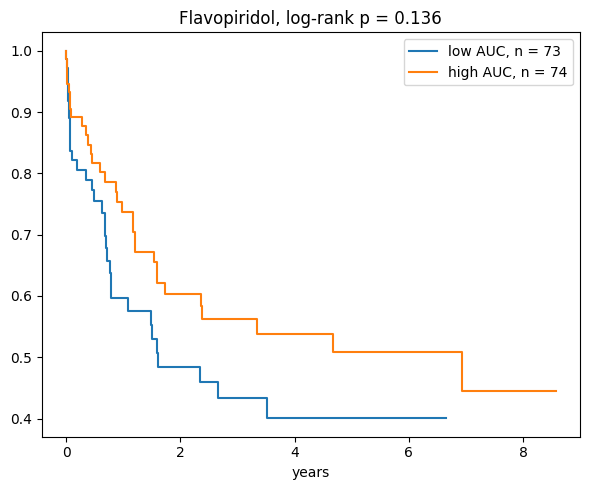

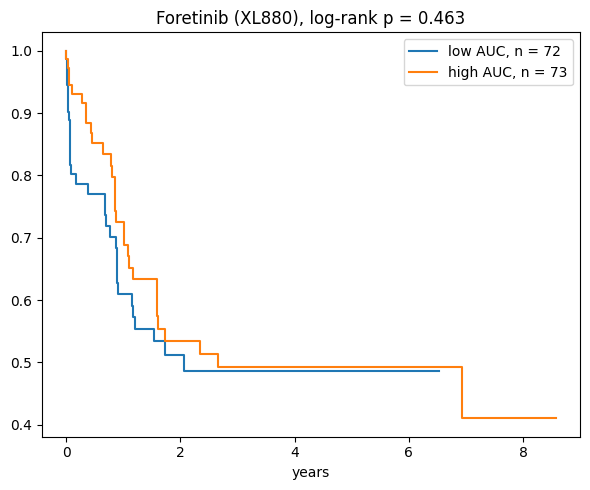

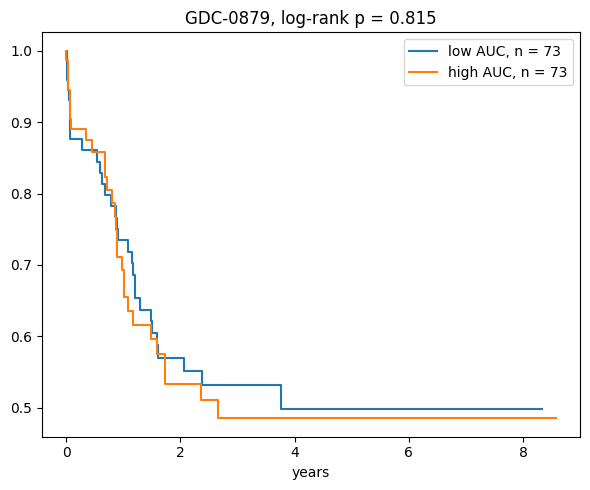

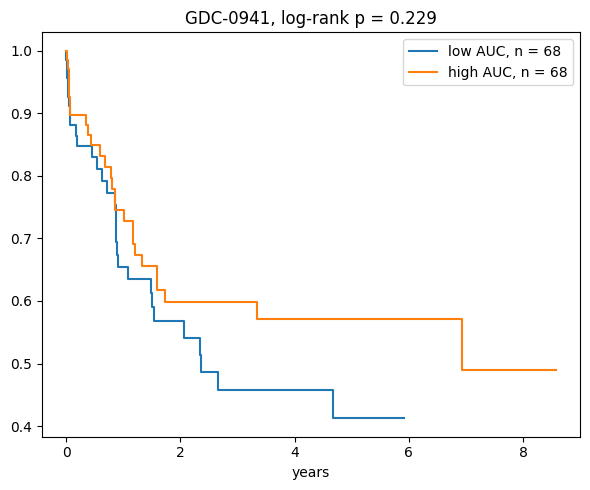

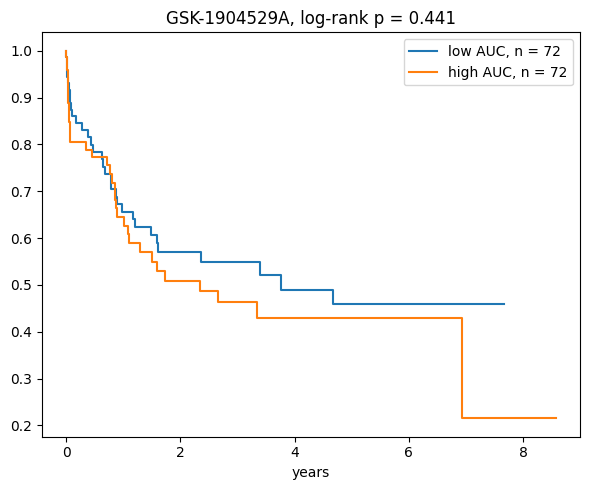

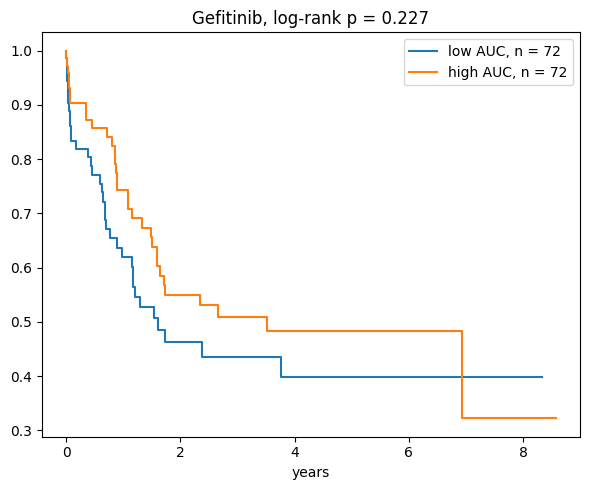

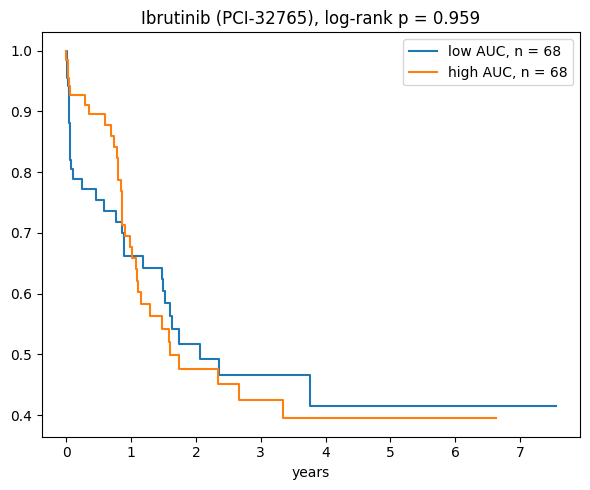

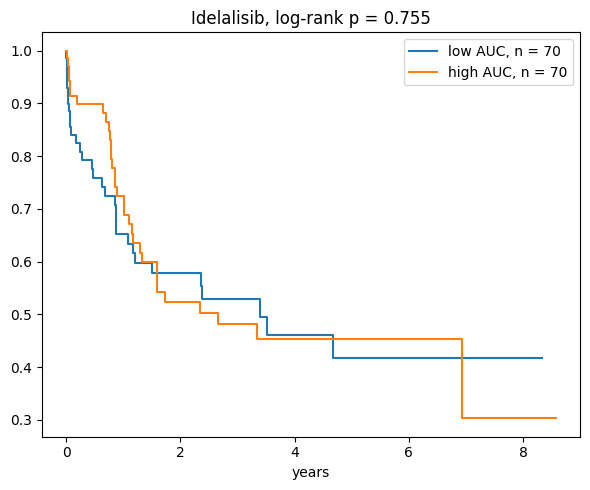

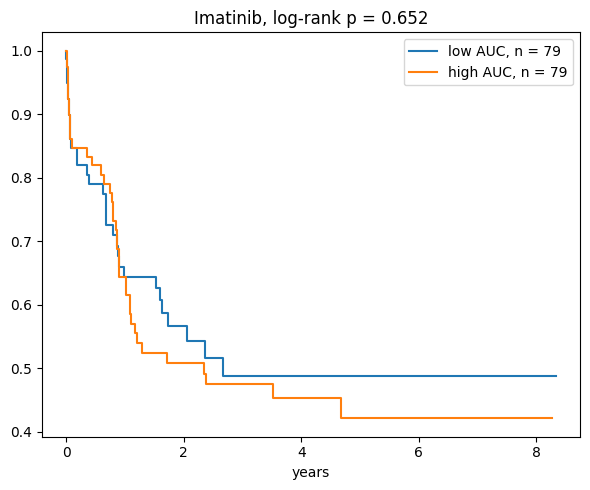

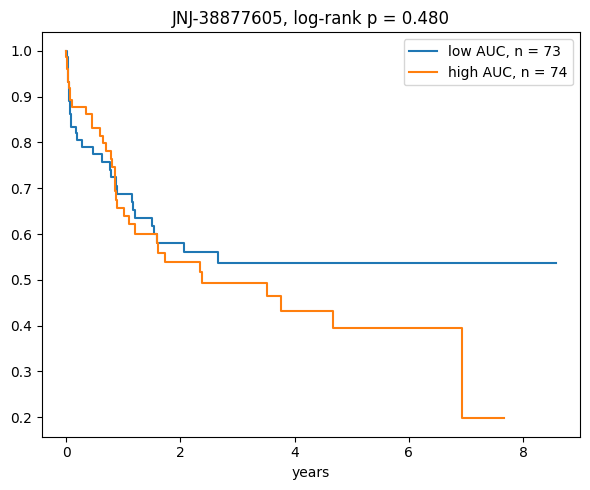

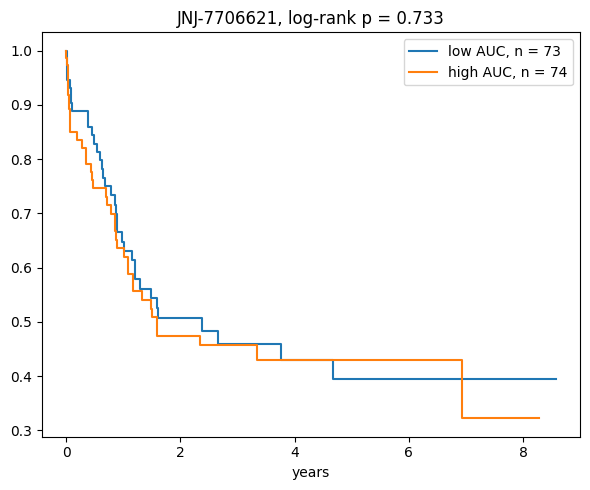

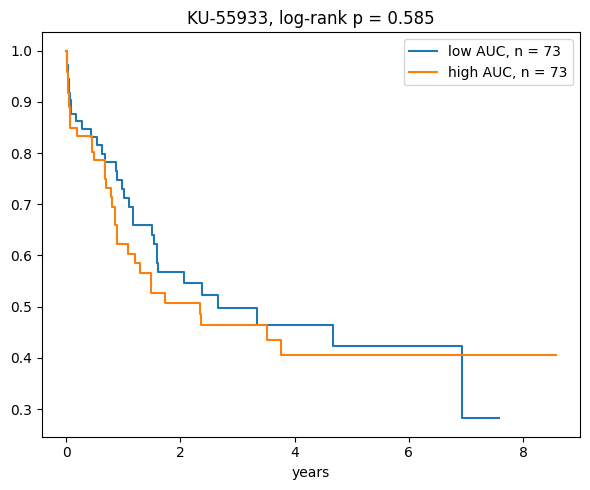

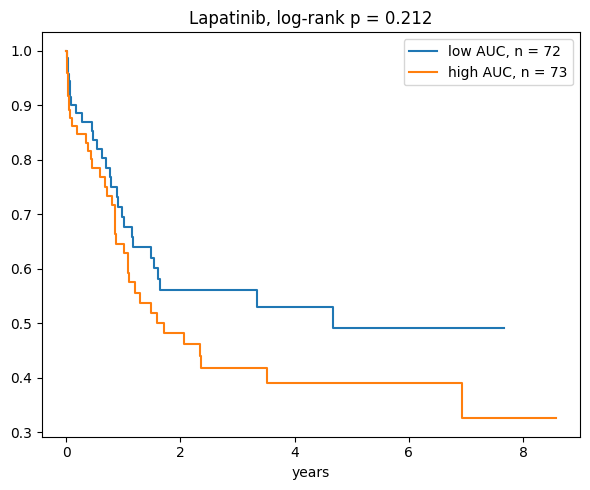

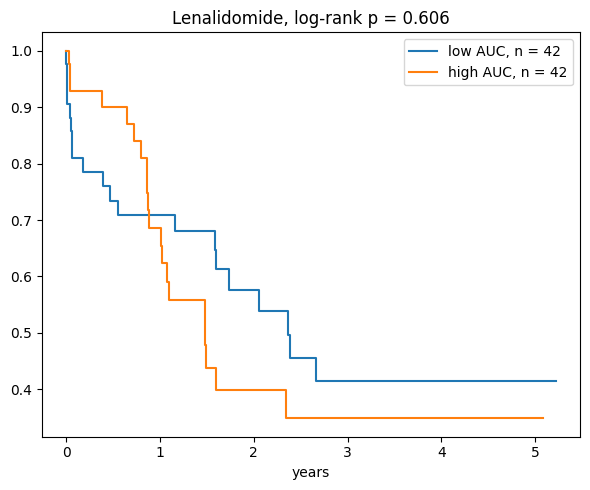

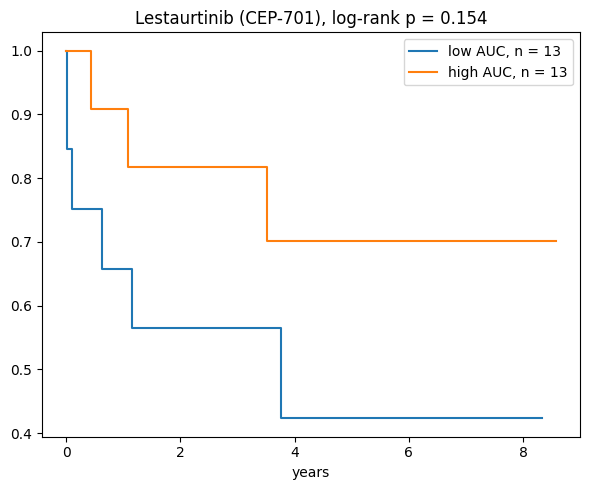

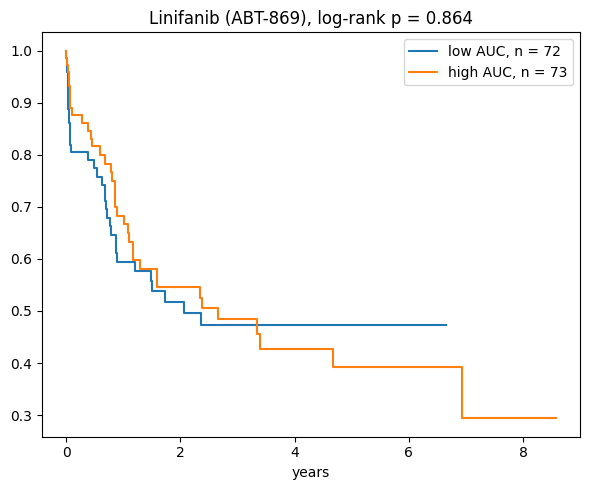

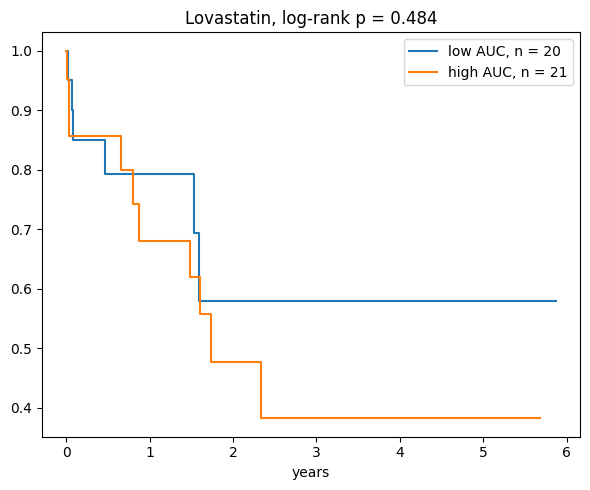

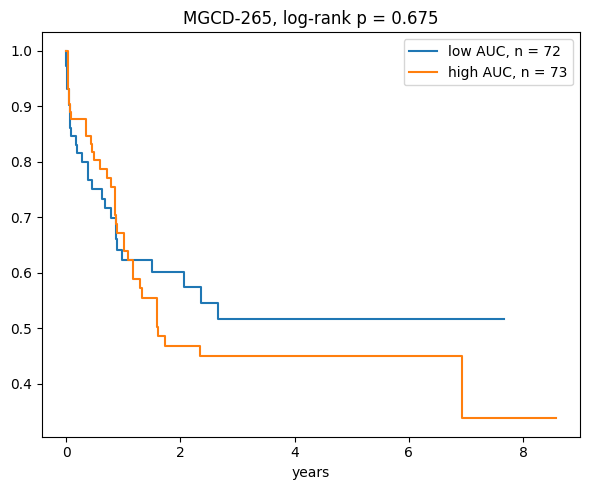

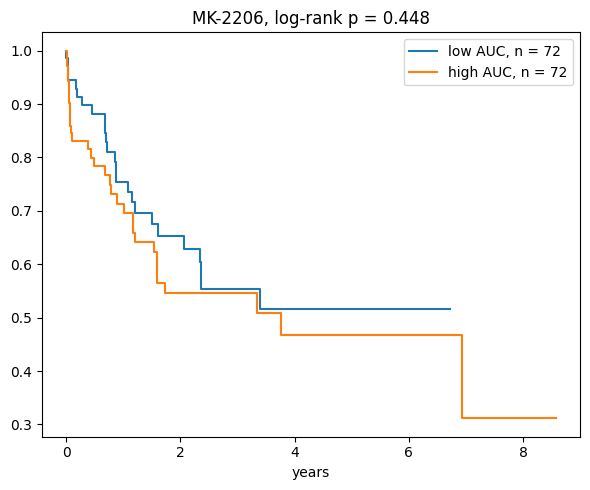

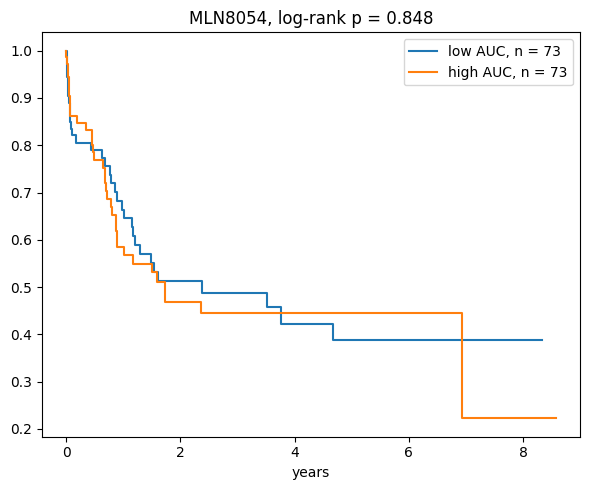

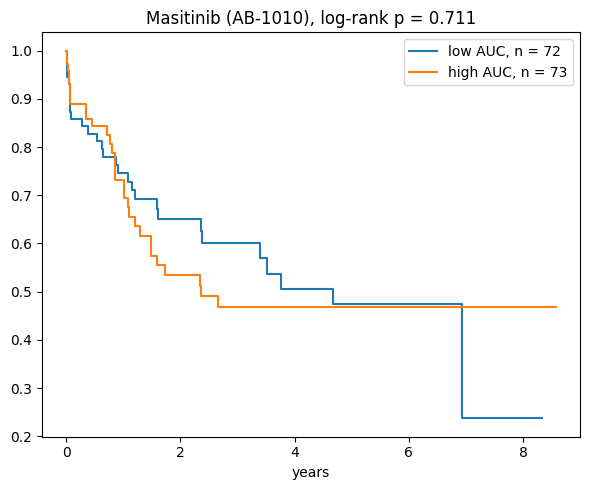

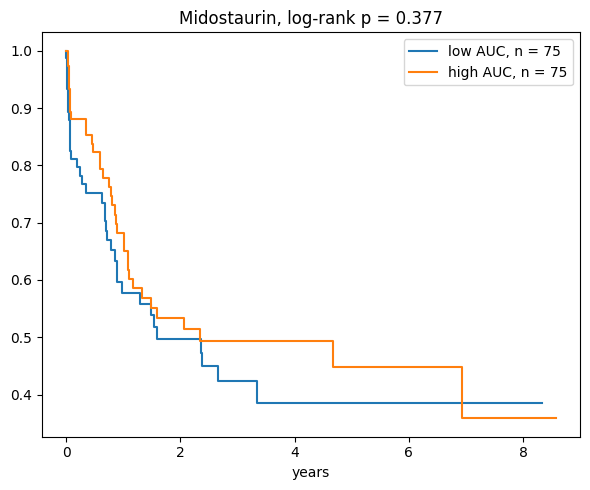

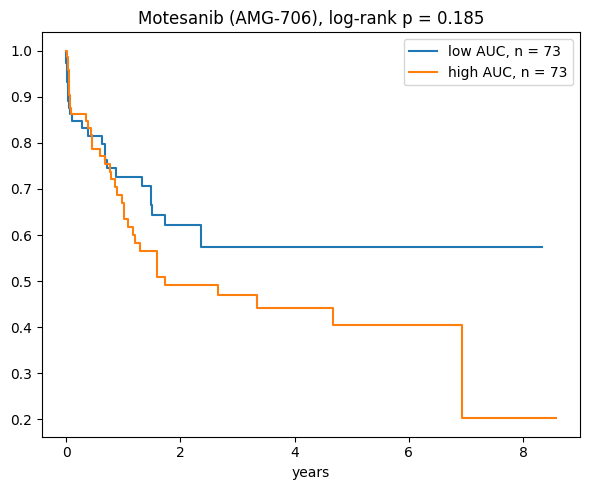

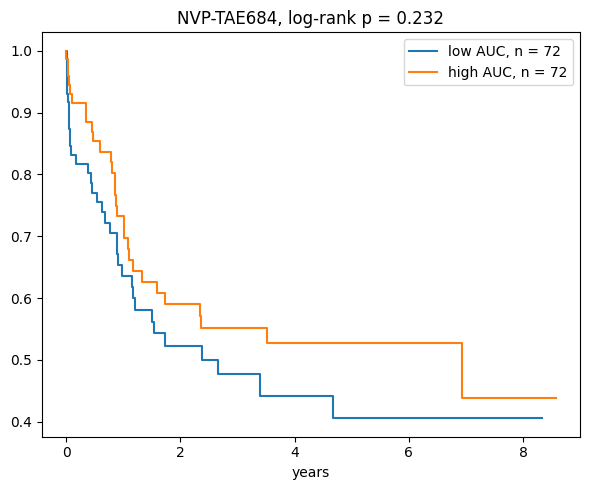

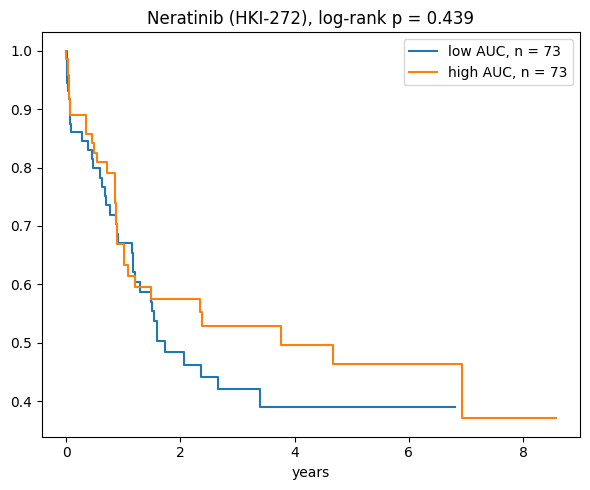

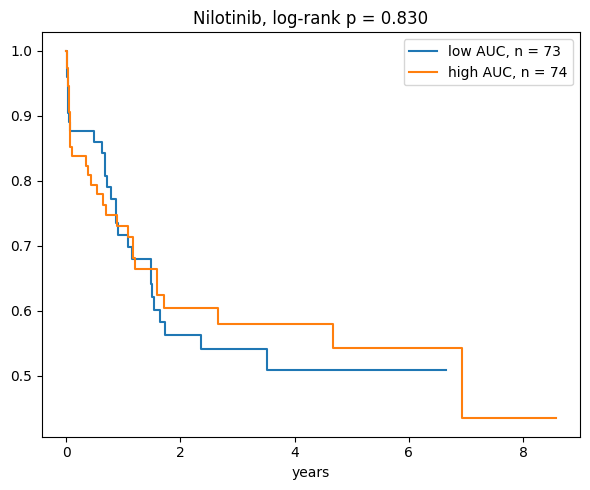

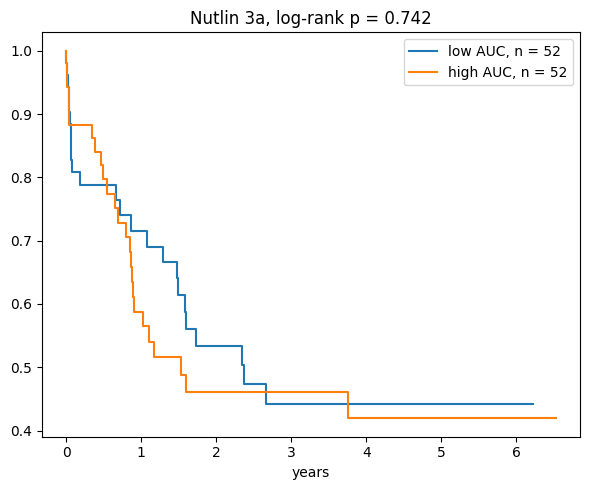

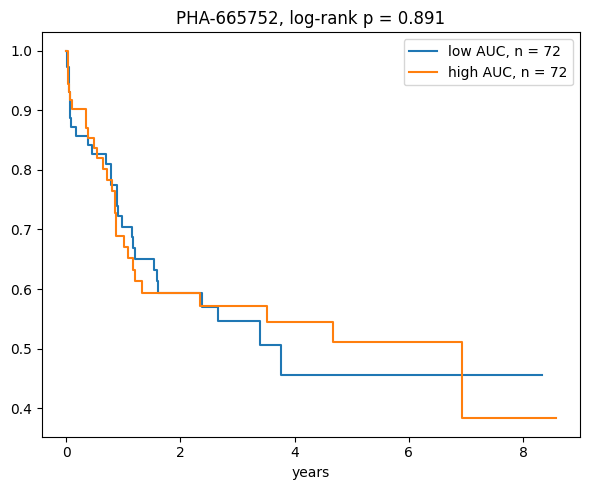

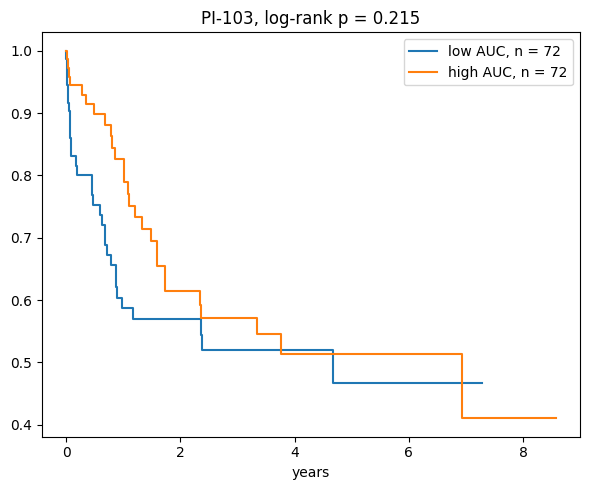

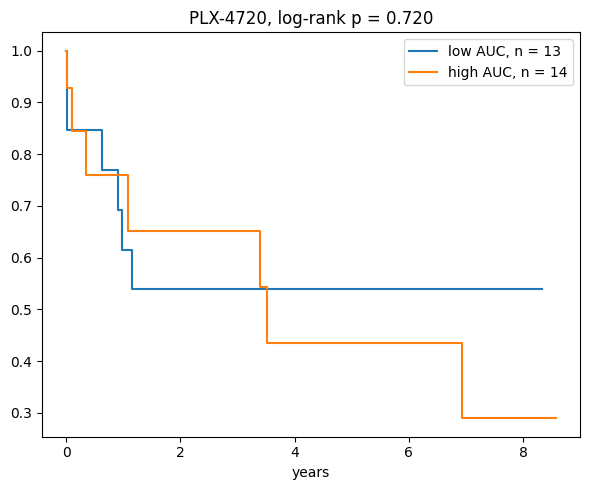

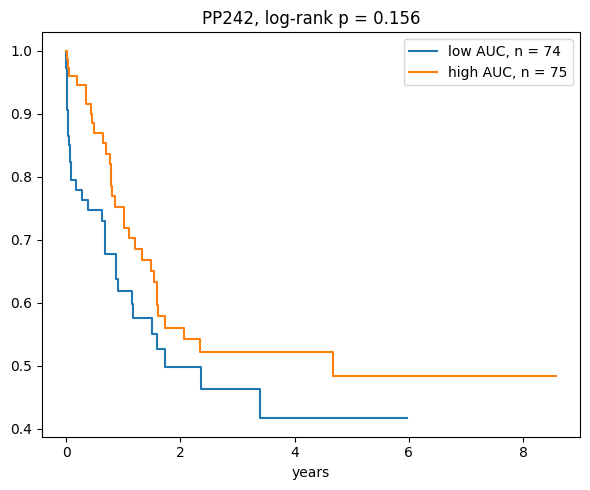

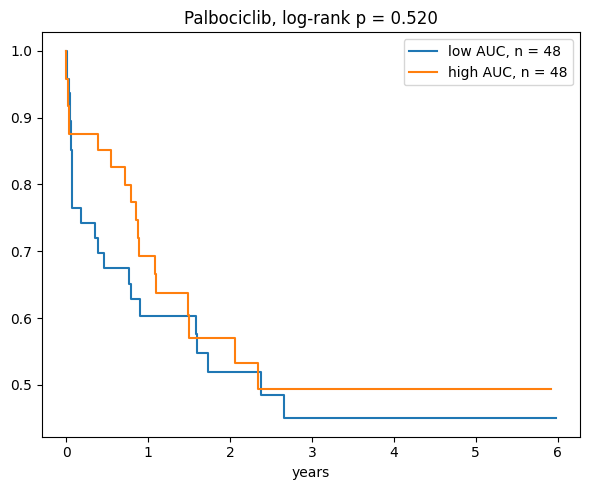

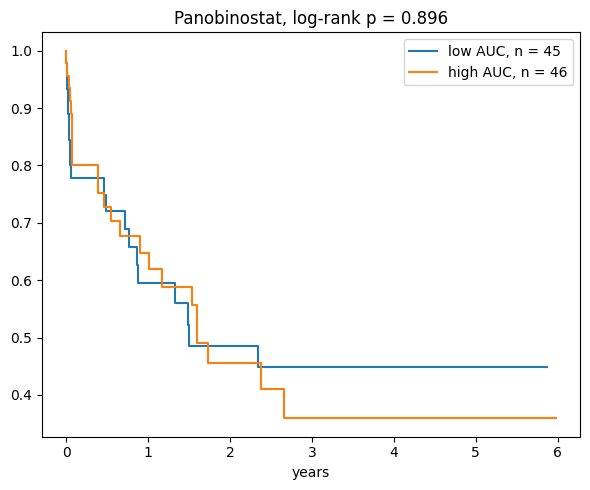

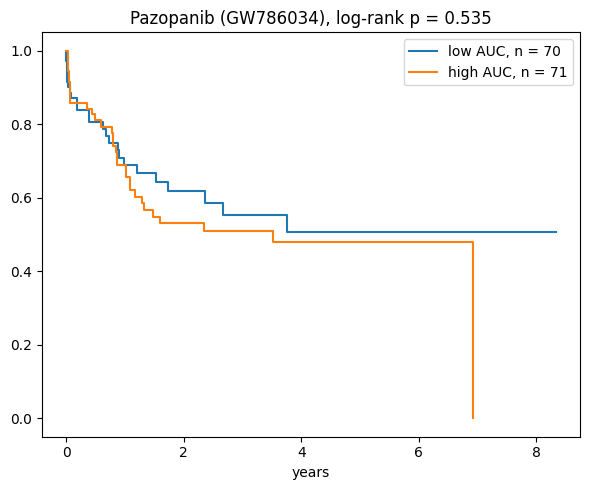

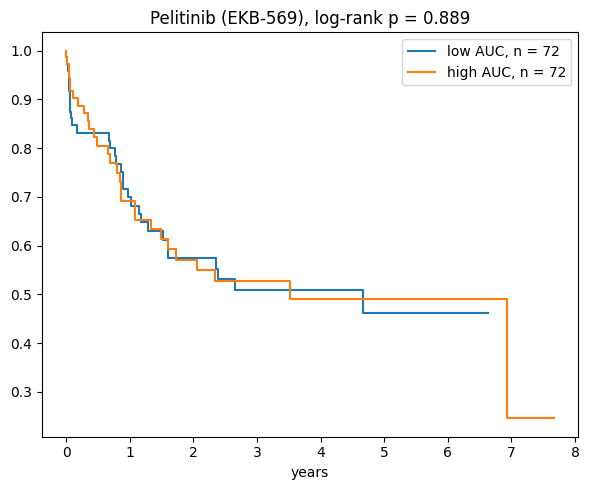

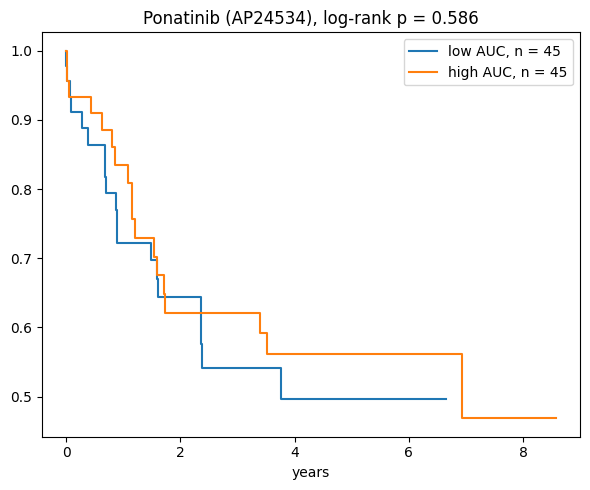

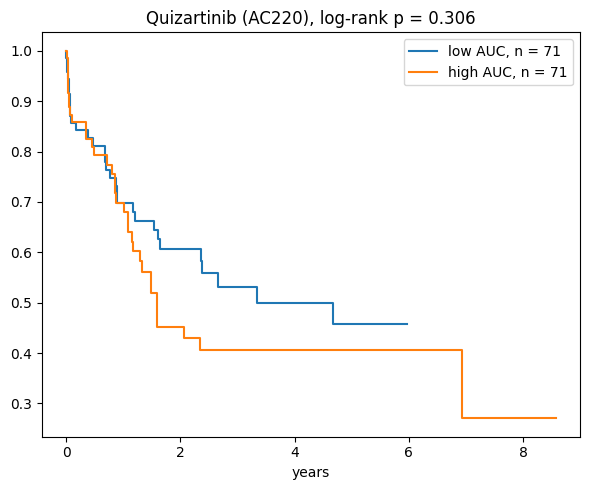

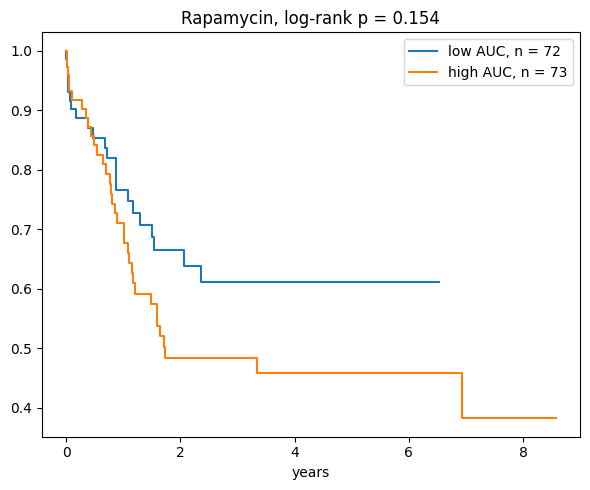

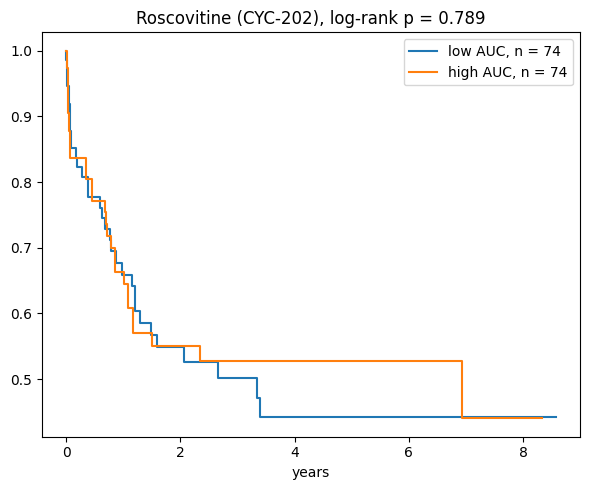

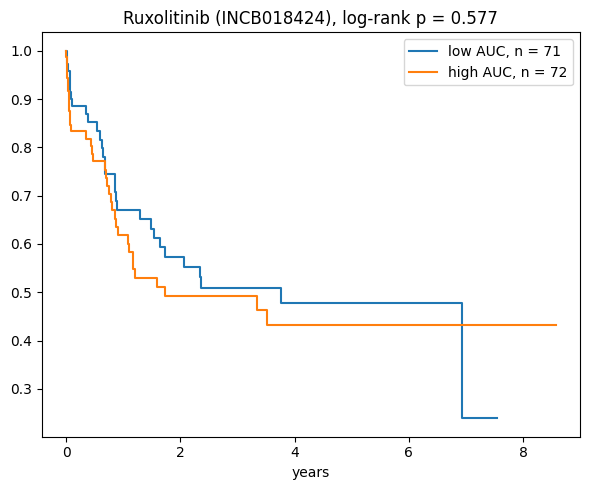

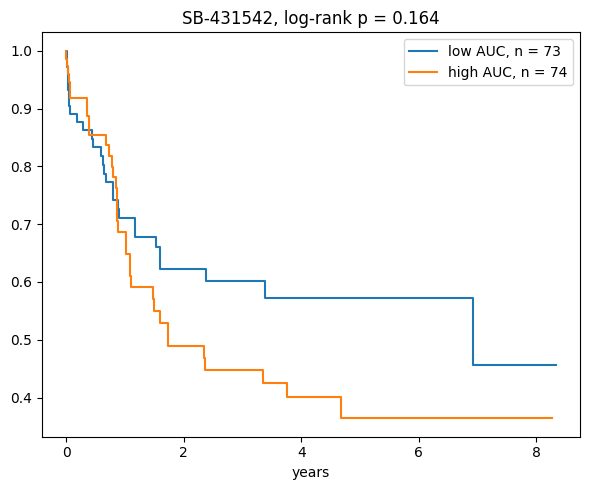

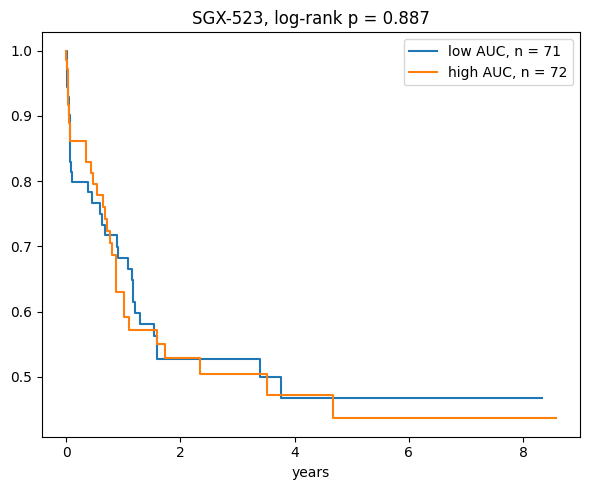

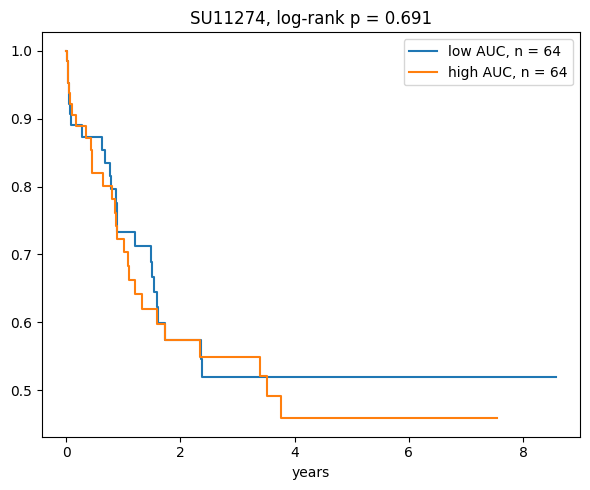

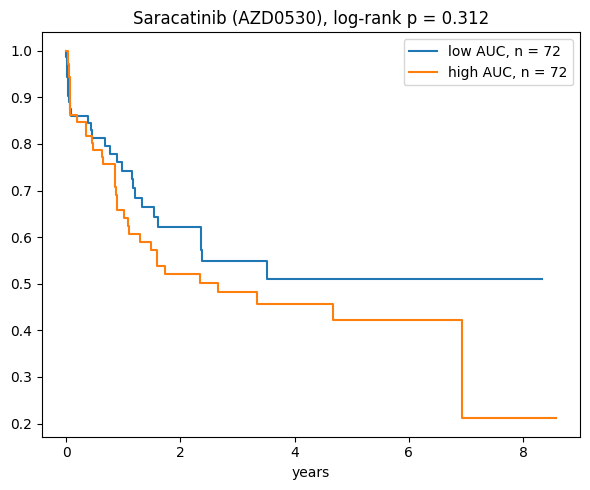

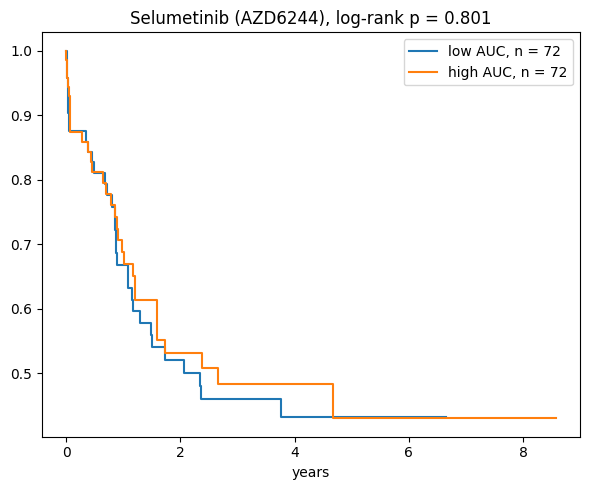

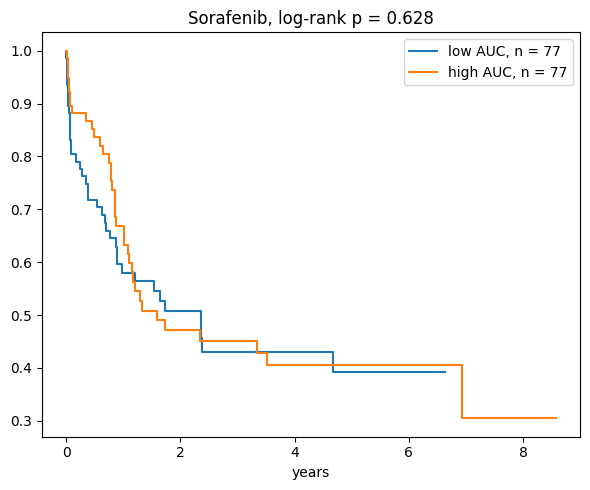

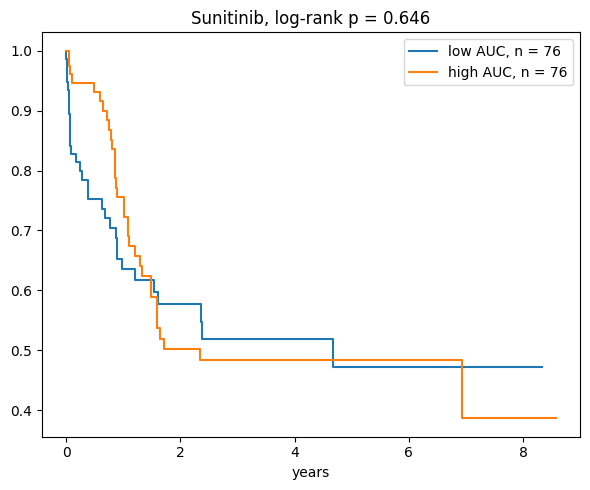

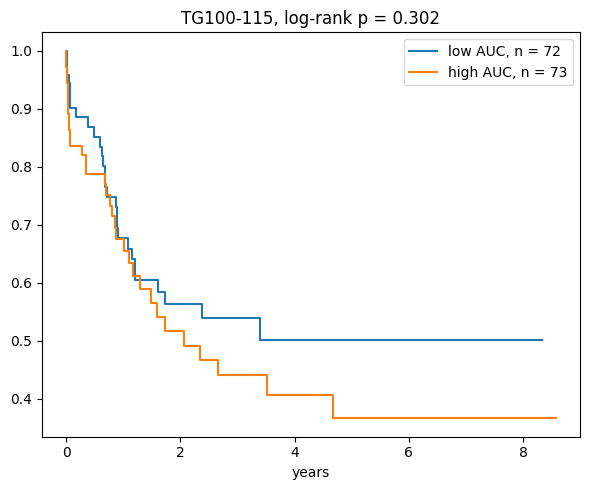

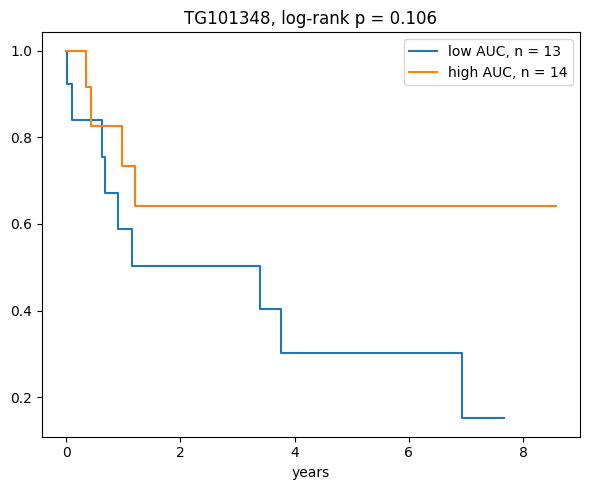

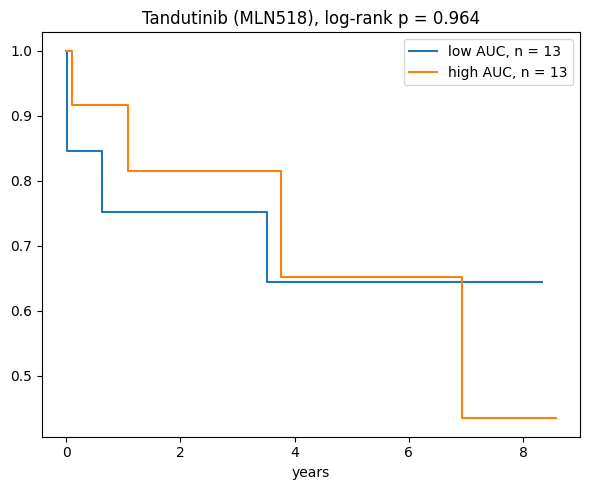

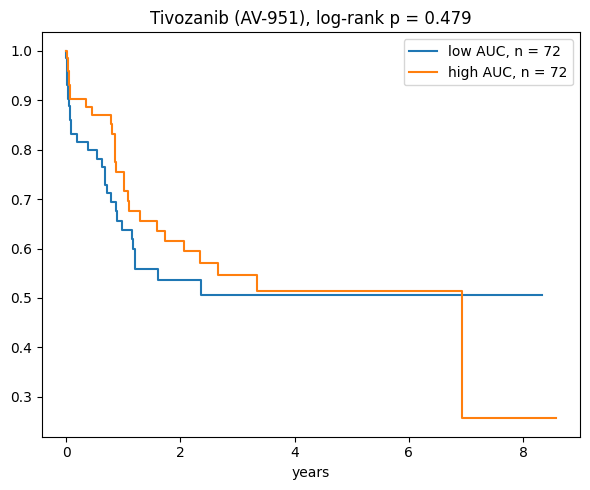

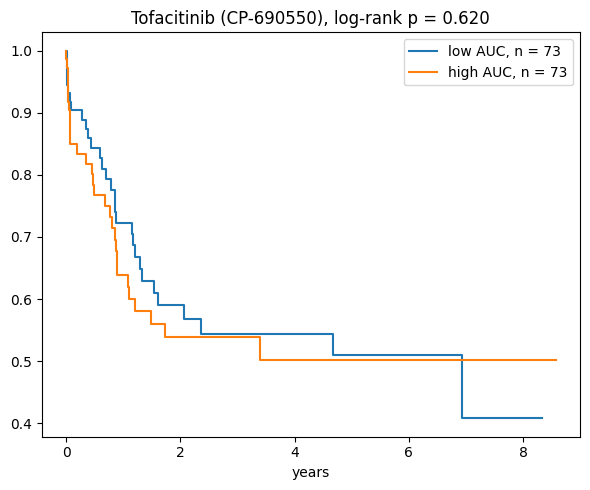

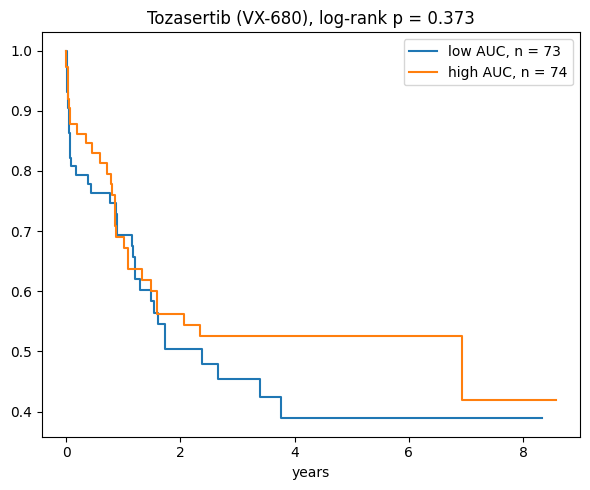

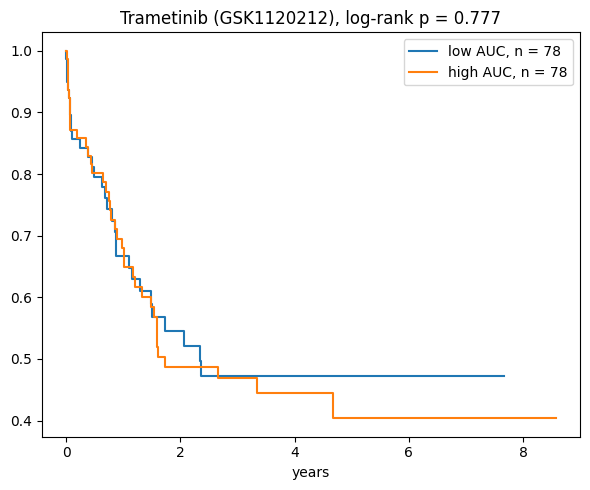

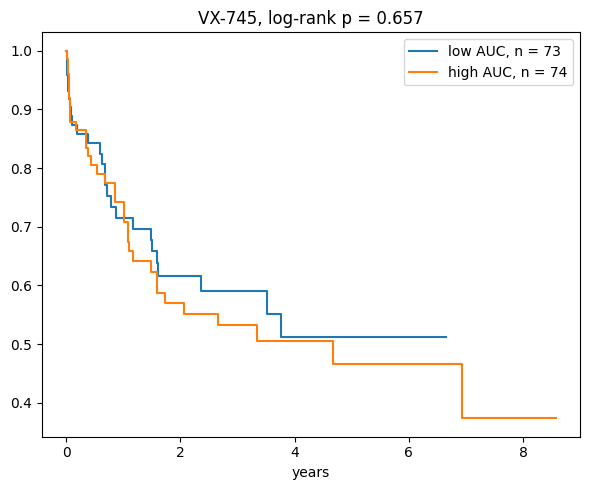

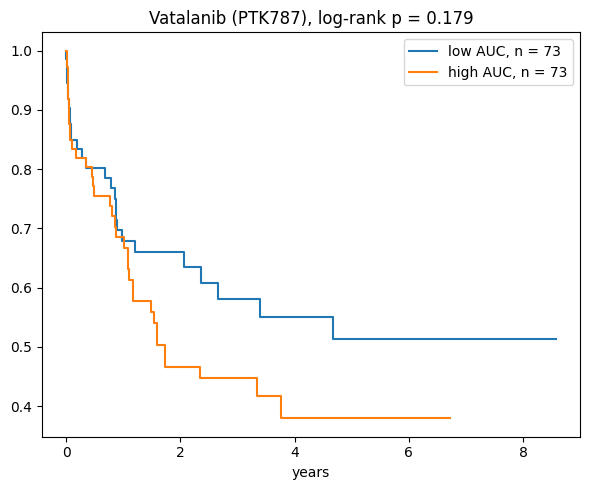

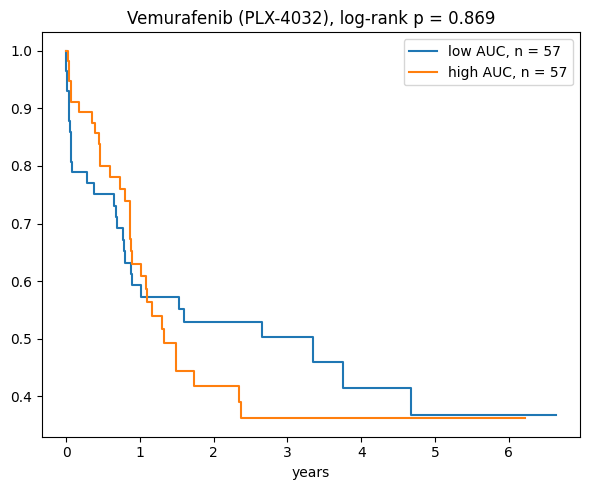

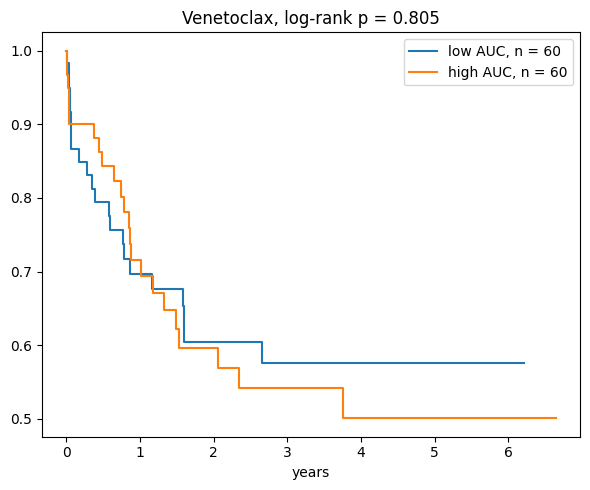

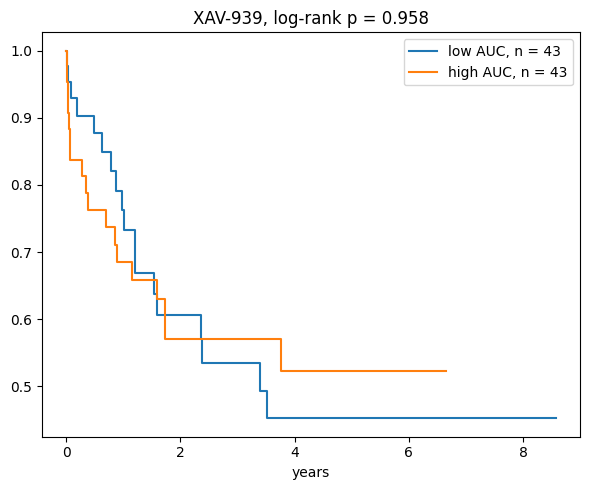

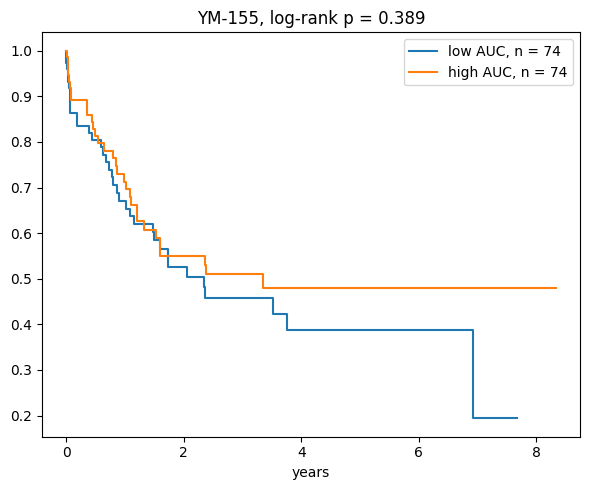

In [6]:
# Kaplan-Meier. Low and high AUC thirds only. The p-value is low versus high.
for name, one in drugs.groupby('inhibitor'):
    auc = one.groupby('dbgap_subject_id')['auc'].mean()
    d = cohort.join(auc.rename('auc')).dropna(subset=['auc']).copy()
    d['band'] = pd.qcut(d.auc.rank(method='first'), 3, labels=['low AUC', 'middle AUC', 'high AUC'])
    d = d[d.band != 'middle AUC']
    fig, ax = plt.subplots(figsize=(6, 5))
    kmf = KaplanMeierFitter()
    for band in ['low AUC', 'high AUC']:
        sub = d[d.band == band]
        kmf.fit(sub.overallSurvival / 365.25, sub.E, label=f'{band}, n = {len(sub)}').plot_survival_function(ax=ax, ci_show=False)
    low = d[d.band == 'low AUC']
    high = d[d.band == 'high AUC']
    lr = logrank_test(high.overallSurvival, low.overallSurvival, high.E, low.E)
    ax.set_title(f'{name}, log-rank p = {lr.p_value:.3f}')
    ax.set_xlabel('years')
    plt.tight_layout()
    plt.show()